# EDAB 6808 Assignment 3: Bayesian Networks and Probabilistic Inference

Heart disease prediction on the Cleveland dataset, using an expert-designed DAG and a DAG learned from the data with bnlearn.

## 1. Data Collection and Preparation

### 1.1 Install libraries

In [ ]:
!pip install bnlearn pgmpy scikit-learn networkx --quiet

### 1.2 Imports

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
import networkx as nx
import pickle
import itertools


import bnlearn as bn

# pgmpy has renamed this class across versions — handle both
try:
    from pgmpy.models import DiscreteBayesianNetwork as BayesianNetwork
except ImportError:
    from pgmpy.models import BayesianNetwork

from pgmpy.estimators import MaximumLikelihoodEstimator, BayesianEstimator, HillClimbSearch

try:
    from pgmpy.estimators import BicScore as BIC_SCORE      # pgmpy <= 1.0
except ImportError:
    from pgmpy.structure_score import BIC as BIC_SCORE      # pgmpy >= 1.1

from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                              precision_score, recall_score, f1_score, roc_auc_score,
                              roc_curve, precision_recall_curve, average_precision_score,
                              classification_report)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Imports successful. pgmpy Bayesian network class loaded as 'BayesianNetwork'.")


Imports successful. pgmpy Bayesian network class loaded as 'BayesianNetwork'.


### 1.3 Upload the dataset

In [ ]:
from google.colab import files
uploaded = files.upload()
LOCAL_PATH = list(uploaded.keys())[0]
print("Uploaded:", LOCAL_PATH)

Saving diabetes (2).csv to diabetes (2) (1).csv
Uploaded: diabetes (2) (1).csv


### 1.4 Inspect the raw file

In [ ]:
with open(LOCAL_PATH, "r") as f:
    for i, line in enumerate(f):
        print(line.strip())
        if i >= 4:
            break

age,gender,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,heartdisease
63,1,1,145,233,1,2,150,0,2.3,3,0,6,0
67,1,4,160,286,0,2,108,1,1.5,2,3,3,2
67,1,4,120,229,0,2,129,1,2.6,2,2,7,1
37,1,3,130,250,0,0,187,0,3.5,3,0,3,0


### 1.5 Detect the file format

In [ ]:
# Standard 14-attribute Cleveland column names
COLUMN_NAMES = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "heartdisease"
]

def robust_read(path):
    # Try 1: no header, comma-separated, "?" as missing
    try:
        df_ = pd.read_csv(path, header=None, names=COLUMN_NAMES, na_values="?")
        if df_.shape[1] == len(COLUMN_NAMES) and pd.to_numeric(df_["age"], errors="coerce").notna().mean() > 0.9:
            return df_, "no header, comma-separated"
    except Exception:
        pass

    # Try 2: file already has its own header row
    try:
        df_ = pd.read_csv(path, na_values="?")
        if df_.shape[1] >= 13:
            return df_, "has header row"
    except Exception:
        pass

    # Try 3: whitespace-delimited, no header
    try:
        df_ = pd.read_csv(path, header=None, names=COLUMN_NAMES, na_values="?", delim_whitespace=True)
        return df_, "no header, whitespace-separated"
    except Exception:
        pass

    raise ValueError("Could not auto-parse the file — send me the raw first 5 lines and I'll fix this manually.")

df, detected_format = robust_read(LOCAL_PATH)
df.columns = [c.strip().lower() for c in df.columns]

print("Detected format:", detected_format)
print("Shape:", df.shape)
df.head()

Detected format: no header, comma-separated
Shape: (304, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,heartdisease
0,age,gender,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,heartdisease
1,63,1,1,145,233,1,2,150,0,2.3,3,0,6,0
2,67,1,4,160,286,0,2,108,1,1.5,2,3,3,2
3,67,1,4,120,229,0,2,129,1,2.6,2,2,7,1
4,37,1,3,130,250,0,0,187,0,3.5,3,0,3,0


### 1.6 Load the dataset with the correct header

In [ ]:
# The file DOES have its own header row (note: it uses "gender" instead of "sex")
df = pd.read_csv(LOCAL_PATH, na_values="?")
df.columns = [c.strip().lower() for c in df.columns]

# Standardise the "gender" column name to "sex" to match the assignment's attribute list
if "gender" in df.columns:
    df = df.rename(columns={"gender": "sex"})

print("Shape:", df.shape)
print("Columns:", list(df.columns))
df.head()

Shape: (303, 14)
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'heartdisease']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,heartdisease
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


### 1.7 Data types and missing values

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   age           303 non-null    int64  
 1   sex           303 non-null    int64  
 2   cp            303 non-null    int64  
 3   trestbps      303 non-null    int64  
 4   chol          303 non-null    int64  
 5   fbs           303 non-null    int64  
 6   restecg       303 non-null    int64  
 7   thalach       303 non-null    int64  
 8   exang         303 non-null    int64  
 9   oldpeak       303 non-null    float64
 10  slope         303 non-null    int64  
 11  ca            299 non-null    float64
 12  thal          301 non-null    float64
 13  heartdisease  303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


In [ ]:
# Coerce everything to numeric (in case any column got read as text/object,
# e.g. if "?" left some columns as strings)
for c in df.columns:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print("Missing values per column:")
print(df.isna().sum())

Missing values per column:
age             0
sex             0
cp              0
trestbps        0
chol            0
fbs             0
restecg         0
thalach         0
exang           0
oldpeak         0
slope           0
ca              4
thal            2
heartdisease    0
dtype: int64


### 1.8 Handle the missing values

In [ ]:
n_before = len(df)
df = df.dropna().reset_index(drop=True)
n_after = len(df)
print(f"Rows before: {n_before}")
print(f"Rows after:  {n_after}  ({n_before-n_after} rows removed, {(n_before-n_after)/n_before:.1%})")

Rows before: 303
Rows after:  297  (6 rows removed, 2.0%)


### 1.9 Create the binary target

In [ ]:
df["heartdisease_bin"] = (df["heartdisease"] > 0).astype(int)

print(df["heartdisease_bin"].value_counts())
print()
print(df["heartdisease_bin"].value_counts(normalize=True))

heartdisease_bin
0    160
1    137
Name: count, dtype: int64

heartdisease_bin
0    0.538721
1    0.461279
Name: proportion, dtype: float64


### 1.10 Target distribution

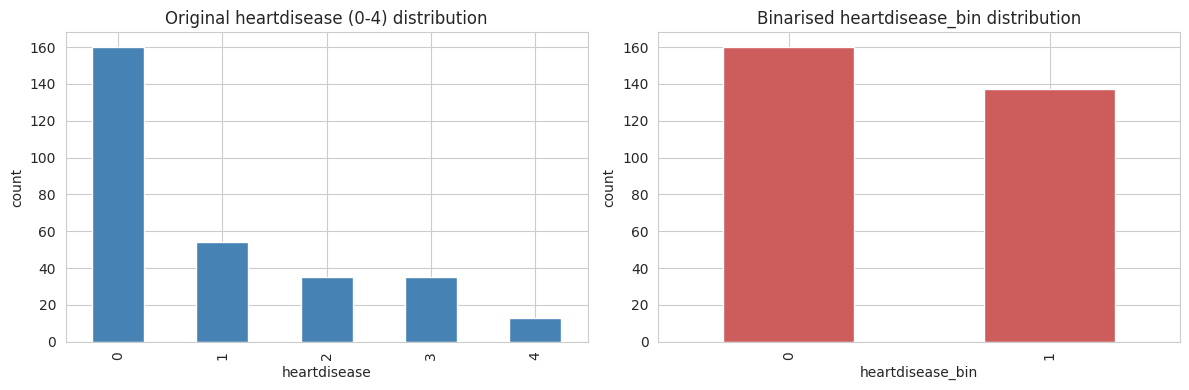

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["heartdisease"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color="steelblue")
ax[0].set_title("Original heartdisease (0-4) distribution")
ax[0].set_xlabel("heartdisease"); ax[0].set_ylabel("count")

df["heartdisease_bin"].value_counts().sort_index().plot(kind="bar", ax=ax[1], color="indianred")
ax[1].set_title("Binarised heartdisease_bin distribution")
ax[1].set_xlabel("heartdisease_bin"); ax[1].set_ylabel("count")
plt.tight_layout(); plt.show()

### 1.11 Summary statistics

In [ ]:
continuous_vars = ["age", "trestbps", "chol", "thalach", "oldpeak"]
df[continuous_vars].describe().T

,count,mean,std,min,25%,50%,75%,max
age,297.0,54.542088,9.049736,29.0,48.0,56.0,61.0,77.0
trestbps,297.0,131.693603,17.762806,94.0,120.0,130.0,140.0,200.0
chol,297.0,247.350168,51.997583,126.0,211.0,243.0,276.0,564.0
thalach,297.0,149.599327,22.941562,71.0,133.0,153.0,166.0,202.0
oldpeak,297.0,1.055556,1.166123,0.0,0.0,0.8,1.6,6.2


### 1.12 Distributions by disease status

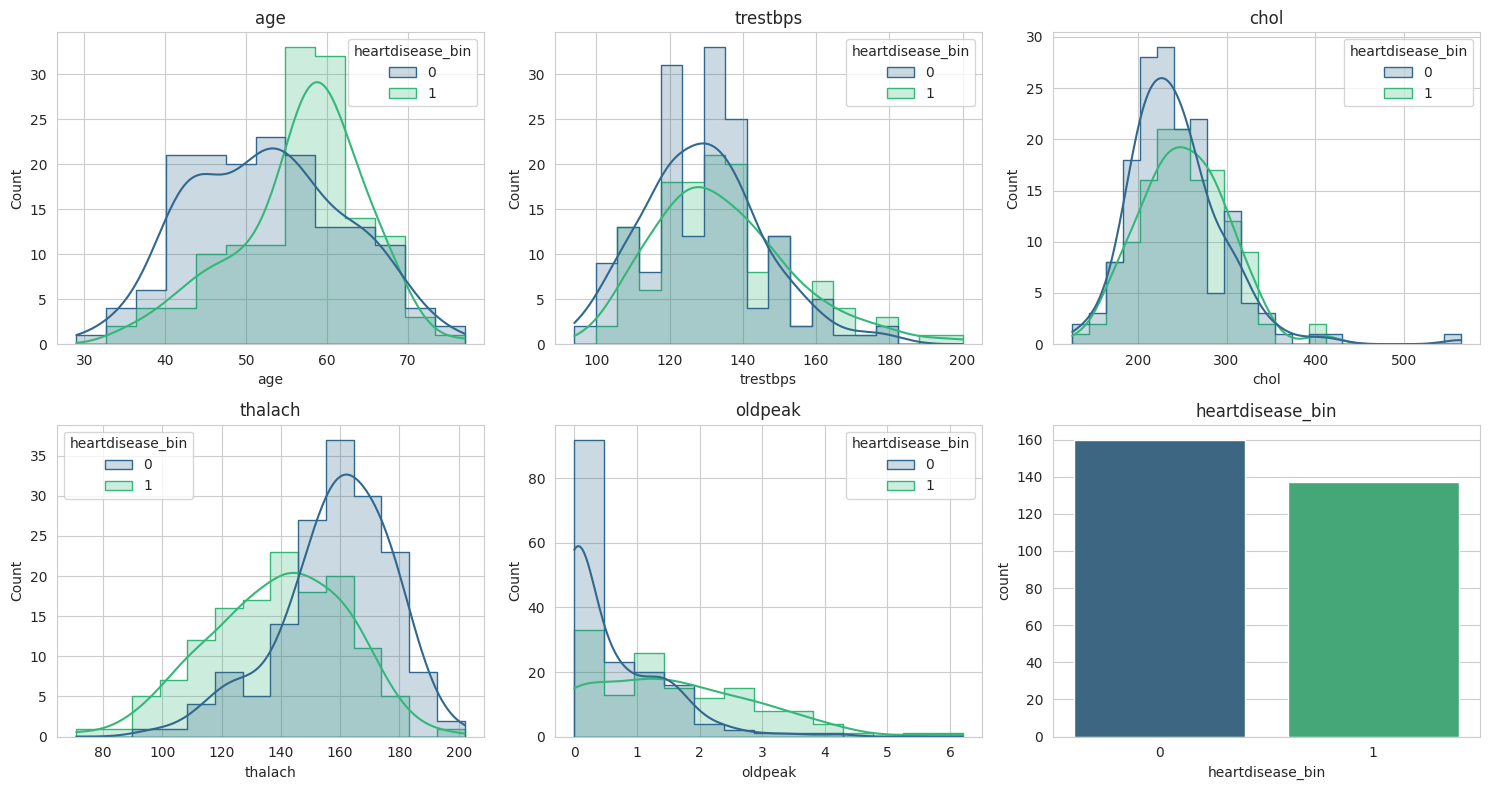

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, continuous_vars + ["heartdisease_bin"]):
    if col == "heartdisease_bin":
        sns.countplot(x=col, data=df, ax=ax, palette="viridis")
    else:
        sns.histplot(data=df, x=col, hue="heartdisease_bin", kde=True, ax=ax,
                     palette="viridis", element="step", common_norm=False)
    ax.set_title(col)
plt.tight_layout(); plt.show()

### 1.13 Correlation heatmap

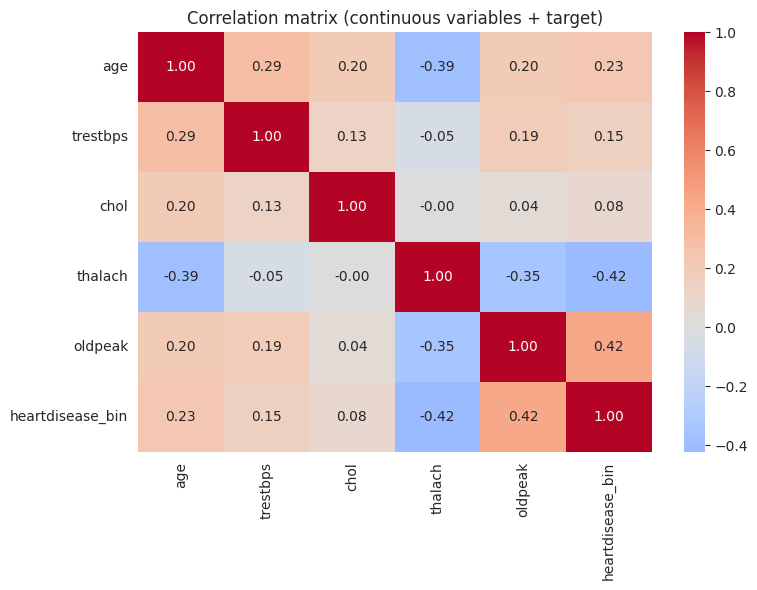

In [ ]:
plt.figure(figsize=(8, 6))
corr = df[continuous_vars + ["heartdisease_bin"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (continuous variables + target)")
plt.tight_layout(); plt.show()

### 1.14 Discretise the continuous variables

In [ ]:
df_disc = df.copy()

# age: clinically-motivated bands
df_disc["age_cat"] = pd.cut(df["age"], bins=[0, 45, 55, 65, 120],
                             labels=["<45", "45-54", "55-64", "65+"])

# trestbps: normal / elevated / high (clinical thresholds)
df_disc["trestbps_cat"] = pd.cut(df["trestbps"], bins=[0, 120, 140, 300],
                                  labels=["normal", "elevated", "high"])

# chol: desirable / borderline / high (NCEP ATP III thresholds)
df_disc["chol_cat"] = pd.cut(df["chol"], bins=[0, 200, 240, 700],
                              labels=["desirable", "borderline", "high"])

# thalach: quantile-based tertiles (no universal clinical cutoff)
df_disc["thalach_cat"] = pd.qcut(df["thalach"], q=3, labels=["low", "medium", "high"])

# oldpeak: 0 = none, then split the positive values
def bin_oldpeak(x):
    if x == 0:
        return "none"
    elif x <= 1:
        return "mild"
    else:
        return "marked"
df_disc["oldpeak_cat"] = df["oldpeak"].apply(bin_oldpeak)

# Cast the already-discrete variables to categories
for c in ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal", "heartdisease_bin"]:
    df_disc[c] = df_disc[c].astype(int).astype("category")

for c in ["age_cat", "trestbps_cat", "chol_cat", "thalach_cat", "oldpeak_cat"]:
    df_disc[c] = df_disc[c].astype("category")

model_cols = ["age_cat", "sex", "cp", "trestbps_cat", "chol_cat", "fbs", "restecg",
              "thalach_cat", "exang", "oldpeak_cat", "slope", "ca", "thal", "heartdisease_bin"]
df_model = df_disc[model_cols].copy()
df_model.head()

,age_cat,sex,cp,trestbps_cat,chol_cat,fbs,restecg,thalach_cat,exang,oldpeak_cat,slope,ca,thal,heartdisease_bin
0,55-64,1,1,high,borderline,1,2,medium,0,marked,3,0,6,0
1,65+,1,4,high,high,0,2,low,1,marked,2,3,3,1
2,65+,1,4,normal,borderline,0,2,low,1,marked,2,2,7,1
3,<45,1,3,elevated,high,0,0,high,0,marked,3,0,3,0
4,<45,0,2,elevated,borderline,0,2,high,0,marked,1,0,3,0


### 1.15 Check the discretised data

In [ ]:
print(df_model.isna().sum())
print()
for c in df_model.columns:
    print(c, "->", df_model[c].value_counts().to_dict())

age_cat             0
sex                 0
cp                  0
trestbps_cat        0
chol_cat            0
fbs                 0
restecg             0
thalach_cat         0
exang               0
oldpeak_cat         0
slope               0
ca                  0
thal                0
heartdisease_bin    0
dtype: int64

age_cat -> {'55-64': 118, '45-54': 85, '<45': 61, '65+': 33}
sex -> {1: 201, 0: 96}
cp -> {4: 142, 3: 83, 2: 49, 1: 23}
trestbps_cat -> {'elevated': 134, 'normal': 97, 'high': 66}
chol_cat -> {'high': 151, 'borderline': 97, 'desirable': 49}
fbs -> {0: 254, 1: 43}
restecg -> {0: 147, 2: 146, 1: 4}
thalach_cat -> {'medium': 107, 'low': 99, 'high': 91}
exang -> {0: 200, 1: 97}
oldpeak_cat -> {'marked': 123, 'none': 96, 'mild': 78}
slope -> {1: 139, 2: 137, 3: 21}
ca -> {0: 174, 1: 65, 2: 38, 3: 20}
thal -> {3: 164, 7: 115, 6: 18}
heartdisease_bin -> {0: 160, 1: 137}


In [ ]:
df_model.head()

,age_cat,sex,cp,trestbps_cat,chol_cat,fbs,restecg,thalach_cat,exang,oldpeak_cat,slope,ca,thal,heartdisease_bin
0,55-64,1,1,high,borderline,1,2,medium,0,marked,3,0,6,0
1,65+,1,4,high,high,0,2,low,1,marked,2,3,3,1
2,65+,1,4,normal,borderline,0,2,low,1,marked,2,2,7,1
3,<45,1,3,elevated,high,0,0,high,0,marked,3,0,3,0
4,<45,0,2,elevated,borderline,0,2,high,0,marked,1,0,3,0


### 1.16 Train and test split

In [ ]:
train_df, test_df = train_test_split(
    df_model, test_size=0.25, random_state=42, stratify=df_model["heartdisease_bin"]
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Training set: {train_df.shape[0]} rows")
print(f"Test set:     {test_df.shape[0]} rows")
print("\nTrain target balance:\n", train_df["heartdisease_bin"].value_counts(normalize=True))
print("\nTest target balance:\n", test_df["heartdisease_bin"].value_counts(normalize=True))

Training set: 222 rows
Test set:     75 rows

Train target balance:
 heartdisease_bin
0    0.540541
1    0.459459
Name: proportion, dtype: float64

Test target balance:
 heartdisease_bin
0    0.533333
1    0.466667
Name: proportion, dtype: float64


In [ ]:
#confirming if frame is ready before building on it
print("df_model:", df_model.shape, " missing:", int(df_model.isna().sum().sum()))
display(pd.DataFrame({
    "variable": df_model.columns,
    "dtype":    [str(df_model[c].dtype) for c in df_model.columns],
    "n_states": [df_model[c].nunique() for c in df_model.columns],
    "states":   [list(map(str, df_model[c].cat.categories))
                 if str(df_model[c].dtype) == "category" else "NOT CATEGORICAL"
                 for c in df_model.columns],
}))

df_model: (297, 14)  missing: 0


,variable,dtype,n_states,states
0,age_cat,category,4,"[<45, 45-54, 55-64, 65+]"
1,sex,category,2,"[0, 1]"
2,cp,category,4,"[1, 2, 3, 4]"
3,trestbps_cat,category,3,"[normal, elevated, high]"
4,chol_cat,category,3,"[desirable, borderline, high]"
5,fbs,category,2,"[0, 1]"
6,restecg,category,3,"[0, 1, 2]"
7,thalach_cat,category,3,"[low, medium, high]"
8,exang,category,2,"[0, 1]"
9,oldpeak_cat,category,3,"[marked, mild, none]"


## 2. Structure Learning

### 2.1 Setup for the network

Before we can build a Bayesian network we need the data in a form pgmpy and bnlearn can work with, and we need to decide up front what values each variable is allowed to take. Getting this wrong causes failures much later, in parameter learning or in prediction, where the cause is hard to trace back. So we deal with it here.

Three things to do:

1. Name the target. We set TARGET once instead of retyping "heartdisease_bin" in every cell through to Section 5.

2. Fix the state space. STATE_NAMES lists the values each variable can take. We take it from df_model rather than train_df deliberately. restecg=1 appears only 4 times in the whole dataset, and since our split only stratifies on the target, all 4 could end up in the test set. Building the state list from training data would give restecg two states instead of three, and the first test patient with restecg=1 would fail with a KeyError. Taking it from the full frame prevents that at no cost, because it only decides which columns the CPT has. The probabilities themselves still come from training rows, so our test set stays unseen.

3. Convert the categoricals to strings. Both libraries look up CPT columns by value, and a pandas Categorical keeps its integer codes separate from its labels, which confuses them. Strings avoid the problem entirely. The trade-off is that evidence in Section 4 has to be quoted, {"sex": "1"} rather than {"sex": 1}, since the unquoted version returns nothing instead of raising an error.

In [ ]:
TARGET     = "heartdisease_bin"
MODEL_COLS = list(df_model.columns)

def states_of(col):
    s = df_model[col]
    if str(s.dtype) == "category":
        return [str(x) for x in s.cat.categories]
    return sorted(str(x) for x in s.unique())

# from df_model, not train_df, so a state that only lands in the test split
# still gets a CPT column
STATE_NAMES = {c: states_of(c) for c in MODEL_COLS}

# pgmpy and bnlearn mishandle pandas categoricals, so we work on string copies
to_bn    = lambda d: d.astype(str).astype(object).copy()
df_bn    = to_bn(df_model)
train_bn = to_bn(train_df)
test_bn  = to_bn(test_df)

print("train / test:", train_bn.shape, test_bn.shape)
print()
for c in MODEL_COLS:
    print(f"  {c:16s} {len(STATE_NAMES[c])} states -> {STATE_NAMES[c]}")

print()
for c in MODEL_COLS:
    absent = set(STATE_NAMES[c]) - set(train_bn[c].unique())
    if absent:
        print(f"  note: {c} states absent from the training split: {sorted(absent)}")

train / test: (222, 14) (75, 14)

  age_cat          4 states -> ['<45', '45-54', '55-64', '65+']
  sex              2 states -> ['0', '1']
  cp               4 states -> ['1', '2', '3', '4']
  trestbps_cat     3 states -> ['normal', 'elevated', 'high']
  chol_cat         3 states -> ['desirable', 'borderline', 'high']
  fbs              2 states -> ['0', '1']
  restecg          3 states -> ['0', '1', '2']
  thalach_cat      3 states -> ['low', 'medium', 'high']
  exang            2 states -> ['0', '1']
  oldpeak_cat      3 states -> ['marked', 'mild', 'none']
  slope            3 states -> ['1', '2', '3']
  ca               4 states -> ['0', '1', '2', '3']
  thal             3 states -> ['3', '6', '7']
  heartdisease_bin 2 states -> ['0', '1']



In [ ]:
#Fix oldpeak order
ORDER = ["none", "mild", "marked"]
for _d in (df_model, train_df, test_df):
    _d["oldpeak_cat"] = _d["oldpeak_cat"].cat.reorder_categories(ORDER, ordered=True)

STATE_NAMES = {c: states_of(c) for c in MODEL_COLS}
df_bn    = to_bn(df_model)
train_bn = to_bn(train_df)
test_bn  = to_bn(test_df)

print(STATE_NAMES["oldpeak_cat"])

['none', 'mild', 'marked']


### 2.2 The expert DAG

In [ ]:
EXPERT_EDGES = [
    # demographics - physiological risk factors
    ("age_cat", "trestbps_cat"),
    ("age_cat", "chol_cat"),
    ("age_cat", "fbs"),
    ("sex",     "chol_cat"),
    # risk factors -> disease
    ("age_cat",  TARGET),
    ("sex",      TARGET),
    ("chol_cat", TARGET),
    # disease - clinical findings
    (TARGET, "cp"),
    ("sex",  "cp"),
    (TARGET, "exang"),
    (TARGET, "restecg"),
    (TARGET, "thal"),
    (TARGET, "ca"),
    (TARGET, "thalach_cat"),
    ("age_cat", "thalach_cat"),
    (TARGET, "oldpeak_cat"),
    ("exang",   "oldpeak_cat"),
    # finding - finding
    ("oldpeak_cat", "slope"),
]

EXPERT_JUSTIFICATION = {
    ("age_cat", "trestbps_cat"): "Arteries stiffen with age, so resting blood pressure rises with it.",
    ("age_cat", "chol_cat"):     "Serum cholesterol accumulates over the life course.",
    ("age_cat", "fbs"):          "Glucose tolerance falls with age, raising fasting blood sugar.",
    ("sex", "chol_cat"):         "Lipid profiles differ by sex, mostly through the oestrogen effect before menopause.",
    ("age_cat", TARGET):         "Age is the strongest non-modifiable risk factor for coronary artery disease.",
    ("sex", TARGET):             "Men carry higher CAD risk than women at any given age.",
    ("chol_cat", TARGET):        "High cholesterol drives atherosclerotic plaque formation.",
    (TARGET, "cp"):              "Chest pain is a symptom the narrowing produces, not a cause of it.",
    ("sex", "cp"):               "Women present with atypical or non-anginal pain more often than men.",
    (TARGET, "exang"):           "Exercise angina is ischaemia showing up when demand outruns a restricted supply.",
    (TARGET, "restecg"):         "ST-T abnormality and LV hypertrophy are consequences of a diseased myocardium.",
    (TARGET, "thal"):            "The thallium scan measures perfusion defects the disease creates.",
    (TARGET, "ca"):              "Vessels coloured by fluoroscopy measure how far the disease has spread.",
    (TARGET, "thalach_cat"):     "Ischaemia caps the heart rate a patient can reach on the treadmill.",
    ("age_cat", "thalach_cat"):  "Maximum heart rate falls with age regardless of disease.",
    (TARGET, "oldpeak_cat"):     "ST depression under exercise is the electrical signature of ischaemia.",
    ("exang", "oldpeak_cat"):    "Angina and ST depression are two readings of the same ischaemic episode.",
    ("oldpeak_cat", "slope"):    "The slope is measured on the same ST segment as the depression.",
}

expert_edge_table = pd.DataFrame(
    [{"parent": p, "child": c, "justification": EXPERT_JUSTIFICATION[(p, c)]}
     for p, c in EXPERT_EDGES])
print(f"Expert DAG: {len(MODEL_COLS)} nodes, {len(EXPERT_EDGES)} edges")
display(expert_edge_table)

# bnlearn object for the library calls, pgmpy object for structural queries
DAG_expert = bn.make_DAG(EXPERT_EDGES, verbose=0)
expert_dag = BayesianNetwork(EXPERT_EDGES)
expert_dag.add_nodes_from(MODEL_COLS)

print("\nAcyclic:", nx.is_directed_acyclic_graph(nx.DiGraph(EXPERT_EDGES)))
print("All 14 variables present:", set(expert_dag.nodes()) == set(MODEL_COLS))

Expert DAG: 14 nodes, 18 edges


,parent,child,justification
0,age_cat,trestbps_cat,"Arteries stiffen with age, so resting blood pr..."
1,age_cat,chol_cat,Serum cholesterol accumulates over the life co...
2,age_cat,fbs,"Glucose tolerance falls with age, raising fast..."
3,sex,chol_cat,"Lipid profiles differ by sex, mostly through t..."
4,age_cat,heartdisease_bin,Age is the strongest non-modifiable risk facto...
5,sex,heartdisease_bin,Men carry higher CAD risk than women at any gi...
6,chol_cat,heartdisease_bin,High cholesterol drives atherosclerotic plaque...
7,heartdisease_bin,cp,Chest pain is a symptom the narrowing produces...
8,sex,cp,Women present with atypical or non-anginal pai...
9,heartdisease_bin,exang,Exercise angina is ischaemia showing up when d...



Acyclic: True
All 14 variables present: True


### 2.3 What the structure costs in parameters

In [ ]:
def complexity_table(dag):
    rows = []
    for n in MODEL_COLS:
        par  = sorted(dag.get_parents(n)) if n in dag.nodes() else []
        ncfg = int(np.prod([len(STATE_NAMES[p]) for p in par])) if par else 1
        rows.append({
            "node": n,
            "parents": ", ".join(par) if par else "(root)",
            "parent_configs": ncfg,
            "free_params": ncfg * (len(STATE_NAMES[n]) - 1),
            "rows_per_config": round(len(train_bn) / ncfg, 1),
        })
    return pd.DataFrame(rows).sort_values("free_params", ascending=False).reset_index(drop=True)

ct = complexity_table(expert_dag)
display(ct)

total = ct["free_params"].sum()
print(f"Total free parameters: {total}")
print(f"Training rows: {len(train_bn)}  ({len(train_bn)/total:.1f} rows per parameter)")

# what a fuller parent set for the target would have cost
for extra in [[], ["trestbps_cat"], ["trestbps_cat", "fbs"]]:
    parents = ["age_cat", "sex", "chol_cat"] + extra
    cfg = int(np.prod([len(STATE_NAMES[p]) for p in parents]))
    print(f"  target with parents {parents}: {cfg} configs, "
          f"{len(train_bn)/cfg:.1f} training rows each")

,node,parents,parent_configs,free_params,rows_per_config
0,heartdisease_bin,"age_cat, chol_cat, sex",24,24,9.2
1,chol_cat,"age_cat, sex",8,16,27.8
2,thalach_cat,"age_cat, heartdisease_bin",8,16,27.8
3,cp,"heartdisease_bin, sex",4,12,55.5
4,trestbps_cat,age_cat,4,8,55.5
5,oldpeak_cat,"exang, heartdisease_bin",4,8,55.5
6,ca,heartdisease_bin,2,6,111.0
7,slope,oldpeak_cat,3,6,74.0
8,fbs,age_cat,4,4,55.5
9,restecg,heartdisease_bin,2,4,111.0


Total free parameters: 114
Training rows: 222  (1.9 rows per parameter)
  target with parents ['age_cat', 'sex', 'chol_cat']: 24 configs, 9.2 training rows each
  target with parents ['age_cat', 'sex', 'chol_cat', 'trestbps_cat']: 72 configs, 3.1 training rows each
  target with parents ['age_cat', 'sex', 'chol_cat', 'trestbps_cat', 'fbs']: 144 configs, 1.5 training rows each


### 2.4 Visualising the expert DAG

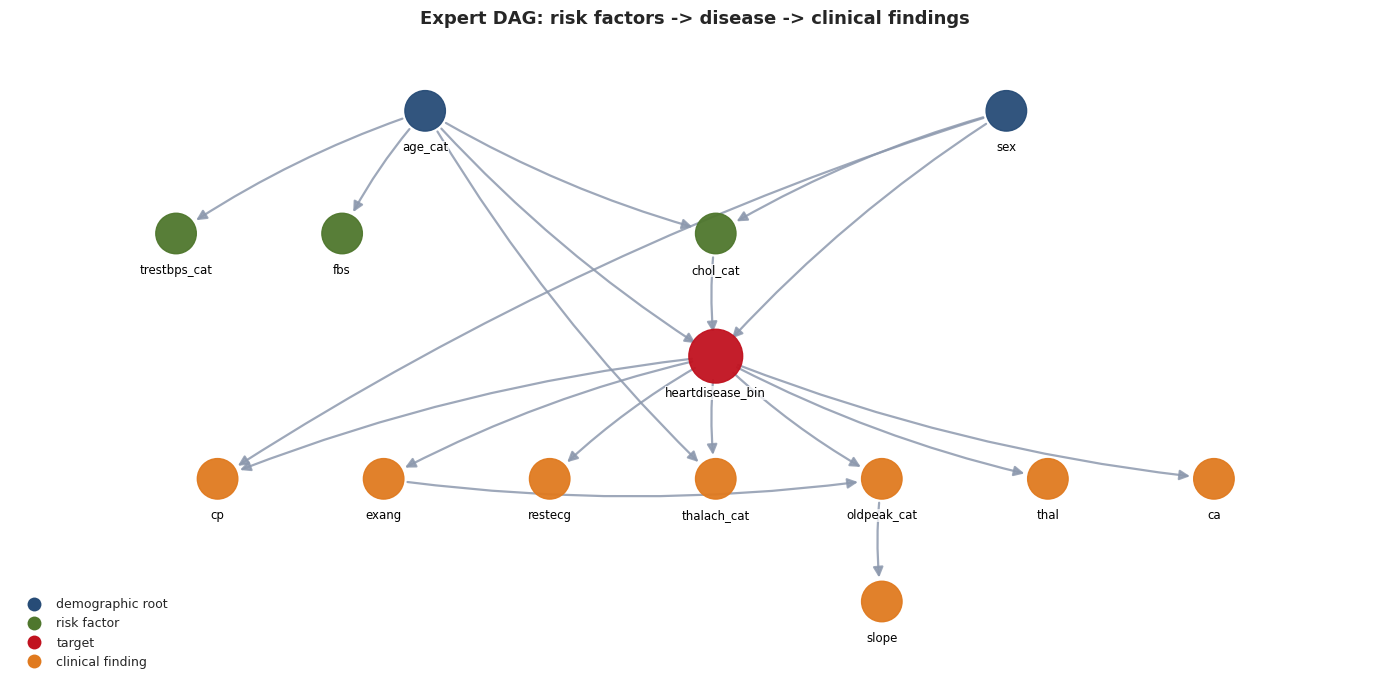

[bnlearn] >Set node properties.
[bnlearn] >Set edge properties.


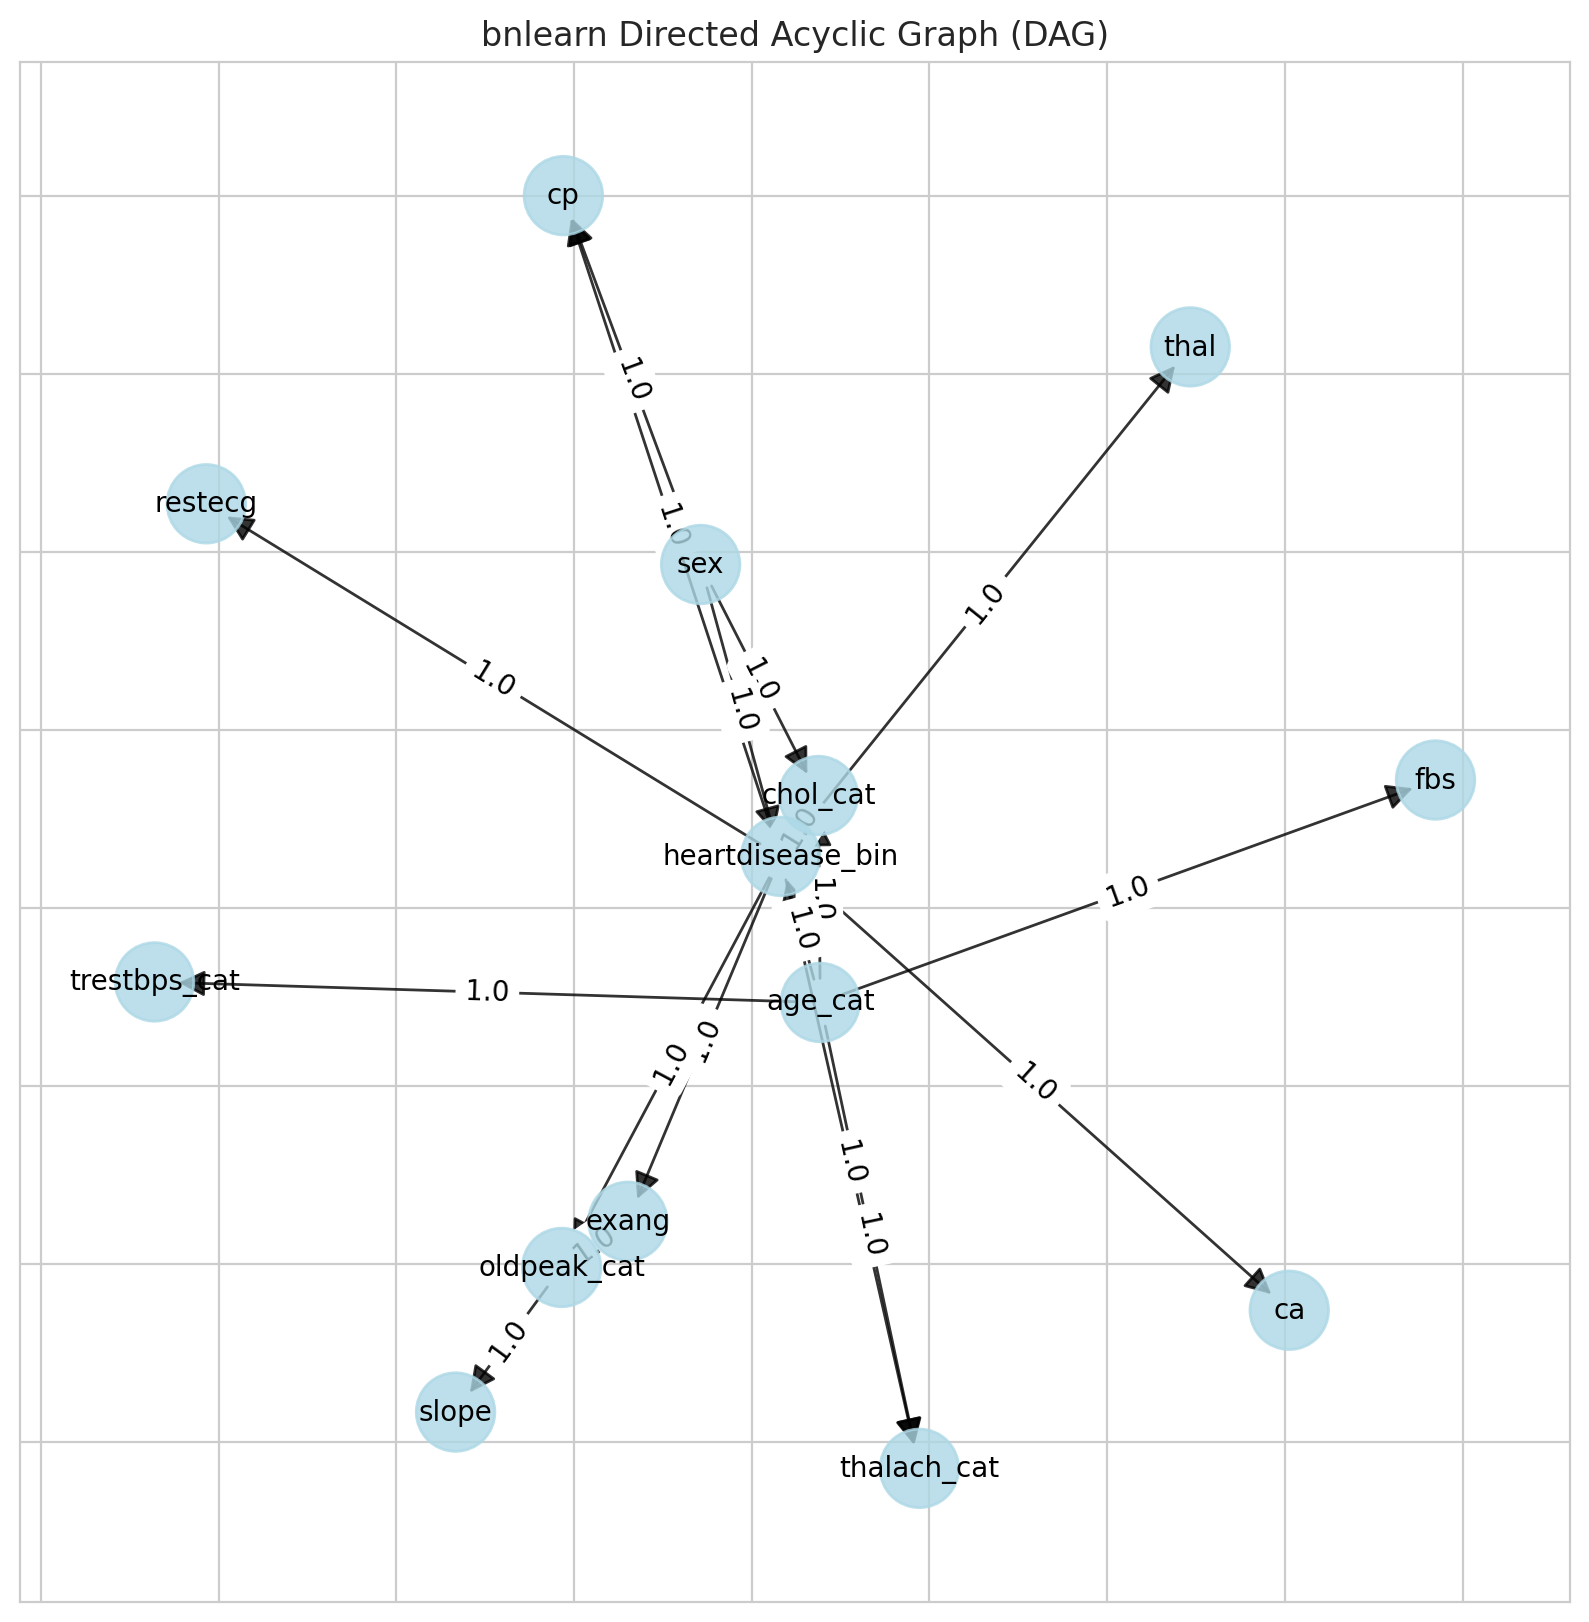

[05-09-2026 11:03:08] [setgraphviz.setgraphviz] [INFO] The OS is not supported to automatically set Graphviz in the system env.
[05-09-2026 11:03:08] [setgraphviz.setgraphviz] [INFO] The OS is not supported to automatically set Graphviz in the system env.
[05-09-2026 11:03:08] [setgraphviz.setgraphviz] [INFO] Graphviz path found in environment.
[05-09-2026 11:03:08] [setgraphviz.setgraphviz] [INFO] Graphviz path found in environment.


In [ ]:



DAG_POS = {
    "age_cat": (-3.5, 4.0), "sex": (3.5, 4.0),
    "trestbps_cat": (-6.5, 3.0), "fbs": (-4.5, 3.0), "chol_cat": (0.0, 3.0),
    TARGET: (0.0, 2.0),
    "cp": (-6.0, 1.0), "exang": (-4.0, 1.0), "restecg": (-2.0, 1.0),
    "thalach_cat": (0.0, 1.0), "oldpeak_cat": (2.0, 1.0), "thal": (4.0, 1.0),
    "ca": (6.0, 1.0),
    "slope": (2.0, 0.0),
}
ROLE_COLOR = {"target": "#c1121f", "root": "#274c77", "risk": "#4f772d", "finding": "#e07a1f"}
NODE_ROLE  = {TARGET: "target", "age_cat": "root", "sex": "root",
              "trestbps_cat": "risk", "chol_cat": "risk", "fbs": "risk"}
role = lambda n: NODE_ROLE.get(n, "finding")

def plot_dag(edges, title, ax=None, pos=DAG_POS, nodes=None, edge_colors=None, legend=False):
    nodes = nodes or MODEL_COLS
    G = nx.DiGraph(); G.add_nodes_from(nodes); G.add_edges_from(edges)
    if ax is None:
        _, ax = plt.subplots(figsize=(14, 7))
    nx.draw_networkx_nodes(G, pos, ax=ax,
                           node_size=[1500 if n == TARGET else 850 for n in G.nodes()],
                           node_color=[ROLE_COLOR[role(n)] for n in G.nodes()], alpha=.95)
    ec = [edge_colors.get(e, "#8d99ae") for e in G.edges()] if edge_colors else "#8d99ae"
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=ec, width=1.6, arrowsize=15,
                           arrowstyle="-|>", node_size=1200,
                           connectionstyle="arc3,rad=0.07", alpha=.85)
    nx.draw_networkx_labels(G, {n: (x, y - 0.30) for n, (x, y) in pos.items()}, ax=ax,
                            font_size=8.5, bbox=dict(fc="white", ec="none", alpha=.75, pad=0.15))
    ax.set_title(title, fontsize=13, fontweight="bold"); ax.margins(0.10); ax.axis("off")
    if legend:
        ax.legend(handles=[Line2D([], [], marker="o", ls="", mfc=c, mec="none", ms=10, label=l)
                           for l, c in [("demographic root", ROLE_COLOR["root"]),
                                        ("risk factor", ROLE_COLOR["risk"]),
                                        ("target", ROLE_COLOR["target"]),
                                        ("clinical finding", ROLE_COLOR["finding"])]],
                  loc="lower left", frameon=False, fontsize=9)
    return ax

fig, ax = plt.subplots(figsize=(14, 7))
plot_dag(EXPERT_EDGES, "Expert DAG: risk factors -> disease -> clinical findings",
         ax=ax, legend=True)
plt.tight_layout(); plt.show()

try:
    bn.plot(DAG_expert, verbose=0)
    bn.plot_graphviz(DAG_expert)
except Exception as e:
    print("bnlearn renderer unavailable:", type(e).__name__, e)

### 2.5 How evidence reaches the target

In [ ]:
parents  = sorted(expert_dag.get_parents(TARGET))
children = sorted(expert_dag.successors(TARGET))
blanket  = sorted(expert_dag.get_markov_blanket(TARGET))
outside  = sorted(set(MODEL_COLS) - set(blanket) - {TARGET})

print("Parents (set the prior risk) :", parents)
print("Children (carry the evidence):", children)
print("Markov blanket               :", blanket)
print("Outside the blanket          :", outside)

und = nx.Graph()
und.add_nodes_from(MODEL_COLS)
und.add_edges_from(EXPERT_EDGES)

paths = []
for v in MODEL_COLS:
    if v == TARGET:
        continue
    p = nx.shortest_path(und, v, TARGET)
    paths.append({"variable": v, "steps": len(p) - 1, "connection": " - ".join(p)})

display(pd.DataFrame(paths).sort_values("steps").reset_index(drop=True))

Our DAG splits the variables around heartdisease_bin into two roles.

The three variables feeding into it, age_cat, sex and chol_cat, establish how likely disease is on patient background alone. This is the starting probability before any test result is known.

Everything the target feeds into, the eight clinical findings, works the other way. Each one is a consequence of the disease, so seeing its value tells us something about whether the disease is present and revises the starting probability accordingly.

We also record the Markov blanket, which is the smallest group of variables that makes the rest of the network redundant for this target. It contains the parents, the children, and any other parent a child happens to have. The useful consequence is that variables falling outside it should have no effect on the diagnosis once everything inside is known.

### 2.6 Testing the expert edges against the data

In [ ]:
# chi-square test on every expert edge
res = bn.independence_test(DAG_expert, train_bn, test="chi_square",
                           alpha=0.05, prune=False, verbose=0)
ind = res["independence_test"]
ind = ind.rename(columns={"source": "parent", "target": "child"})

edge_evidence = expert_edge_table.merge(ind, on=["parent", "child"], how="left")
edge_evidence["supported"] = edge_evidence["stat_test"].map({True: "yes", False: "no"})
edge_evidence = edge_evidence[["parent", "child", "chi_square", "dof",
                               "p_value", "supported", "justification"]]
edge_evidence = edge_evidence.sort_values("p_value").reset_index(drop=True)

display(edge_evidence.round(4))

n_ok = (edge_evidence["supported"] == "yes").sum()
print("Edges supported at alpha = 0.05:", n_ok, "of", len(edge_evidence))

failed = edge_evidence[edge_evidence["supported"] == "no"]
print("\nNot supported by the marginal test:")
display(failed[["parent", "child", "p_value"]])

,parent,child,chi_square,dof,p_value,supported,justification
0,oldpeak_cat,slope,73.1299,4,0.0000,yes,The slope is measured on the same ST segment a...
1,heartdisease_bin,thal,57.4610,2,0.0000,yes,The thallium scan measures perfusion defects t...
2,heartdisease_bin,cp,60.5289,3,0.0000,yes,Chest pain is a symptom the narrowing produces...
3,heartdisease_bin,ca,45.2616,3,0.0000,yes,Vessels coloured by fluoroscopy measure how fa...
4,heartdisease_bin,exang,32.7390,1,0.0000,yes,Exercise angina is ischaemia showing up when d...
5,heartdisease_bin,thalach_cat,31.6538,2,0.0000,yes,Ischaemia caps the heart rate a patient can re...
6,heartdisease_bin,oldpeak_cat,23.2500,2,0.0000,yes,ST depression under exercise is the electrical...
7,age_cat,thalach_cat,32.9567,6,0.0000,yes,Maximum heart rate falls with age regardless o...
8,age_cat,heartdisease_bin,23.8694,3,0.0000,yes,Age is the strongest non-modifiable risk facto...
9,age_cat,trestbps_cat,26.9334,6,0.0001,yes,"Arteries stiffen with age, so resting blood pr..."


Edges supported at alpha = 0.05: 14 of 18

Not supported by the marginal test:


,parent,child,p_value
14,sex,chol_cat,0.069554
15,sex,cp,0.070082
16,chol_cat,heartdisease_bin,0.120907
17,age_cat,chol_cat,0.179646


In [ ]:
res_pruned = bn.independence_test(DAG_expert, train_bn, test="chi_square",
                                  alpha=0.05, prune=True, verbose=0)
expert_pruned_edges = [tuple(e) for e in res_pruned["model_edges"]]

dropped = []
for edge in EXPERT_EDGES:
    if edge not in expert_pruned_edges:
        dropped.append(edge[0] + " -> " + edge[1])

print("Pruning would keep", len(expert_pruned_edges), "of", len(EXPERT_EDGES), "edges")
print("Dropped:", dropped)

[bnlearn] >Converting source-target into adjacency matrix..
[bnlearn] >Making the matrix symmetric..
Pruning would keep 14 of 18 edges
Dropped: ['age_cat -> chol_cat', 'sex -> chol_cat', 'chol_cat -> heartdisease_bin', 'sex -> cp']


14 of the 18 edges pass a chi-square test at the 5% level. The disease-to-finding edges all pass, and by a wide margin, with thal, cp and ca giving the biggest test statistics. Age and sex also hold up as risk factors for the target.

Of the four that fail, three involve cholesterol and one is the edge from sex into chest pain type at p = 0.070, which is a near miss.

The cholesterol result makes sense given how this data was collected. Everyone in the Cleveland sample had already been referred for angiography, so they were symptomatic enough to justify an invasive test. Cholesterol does its damage over decades, and by referral it has already done it, so one reading at that point adds little on top of age and sex.

We are keeping all four edges. The clinical reasoning behind them is sound, and pruning them would strip every connection to chol_cat and leave it isolated in the graph.

### 2.7 Learning a DAG from the data

In [ ]:
BLACK_LIST = []
for root in ["age_cat", "sex"]:
    for c in MODEL_COLS:
        if c != root:
            BLACK_LIST.append((c, root))

sl_plain = bn.structure_learning.fit(train_bn, methodtype="hc", scoretype="bic", verbose=0)
edges_plain = [tuple(e) for e in sl_plain["model_edges"]]

sl_black = bn.structure_learning.fit(train_bn, methodtype="hc", scoretype="bic",
                                     black_list=BLACK_LIST, bw_list_method="edges",
                                     tabu_length=100, verbose=0)
edges_black = [tuple(e) for e in sl_black["model_edges"]]

print("Unconstrained:", len(edges_plain), "edges")
print("Blacklisted  :", len(edges_black), "edges")

into_roots = []
for u, v in edges_plain:
    if v in ("age_cat", "sex"):
        into_roots.append(u + " into " + v)
print("\nEdges pointing into age or sex when unconstrained:", into_roots or "none")

print("\nUnconstrained edges:")
display(pd.DataFrame(edges_plain, columns=["parent", "child"]))
print("Blacklisted edges:")
display(pd.DataFrame(edges_black, columns=["parent", "child"]))

Unconstrained: 9 edges
Blacklisted  : 8 edges

Edges pointing into age or sex when unconstrained: ['thal into sex', 'heartdisease_bin into age_cat']

Unconstrained edges:


,parent,child
0,cp,heartdisease_bin
1,thalach_cat,oldpeak_cat
2,oldpeak_cat,slope
3,thal,sex
4,heartdisease_bin,thal
5,heartdisease_bin,ca
6,heartdisease_bin,exang
7,heartdisease_bin,thalach_cat
8,heartdisease_bin,age_cat


Blacklisted edges:


,parent,child
0,sex,thal
1,cp,heartdisease_bin
2,thalach_cat,oldpeak_cat
3,oldpeak_cat,slope
4,heartdisease_bin,thal
5,heartdisease_bin,ca
6,heartdisease_bin,exang
7,heartdisease_bin,thalach_cat


Our second network comes from hill climbing with the BIC score. The algorithm begins with no edges and repeatedly applies whichever single edge change lifts the score the most, halting once no change helps. That is a greedy approach, but 14 variables generate far more possible graphs than could ever be checked one by one. BIC balances how well the graph fits against how many parameters it needs, charging around 2.7 per parameter at our sample size. Since 114 parameters on 222 rows is already stretched, a score that discourages further growth suits us.

We ran the search twice. The first pass, with no restrictions, returned two edges that cannot be true: one from heart disease to age, another from thal to sex. No measurement in a patient file causes their age or sex, so we blocked all arrows entering those two nodes and repeated the search. The thal edge then pointed from sex to thal, which reads sensibly, and the age edge vanished. Everything that follows uses the constrained result.

What comes back is far leaner than our own graph, 8 edges to our 18. It keeps the diagnostic core intact, with thal, ca, exang and thalach all descending from the target exactly as we drew them. Chest pain is the exception, running into the target rather than away from it. Six of the variables end up with no connections whatsoever.

### 2.8 The learned DAG

Learned DAG: 8 edges
Isolated nodes: ['age_cat', 'trestbps_cat', 'chol_cat', 'fbs', 'restecg']
Parents of target : ['cp']
Children of target: ['ca', 'exang', 'thal', 'thalach_cat']
Markov blanket    : ['ca', 'cp', 'exang', 'sex', 'thal', 'thalach_cat']


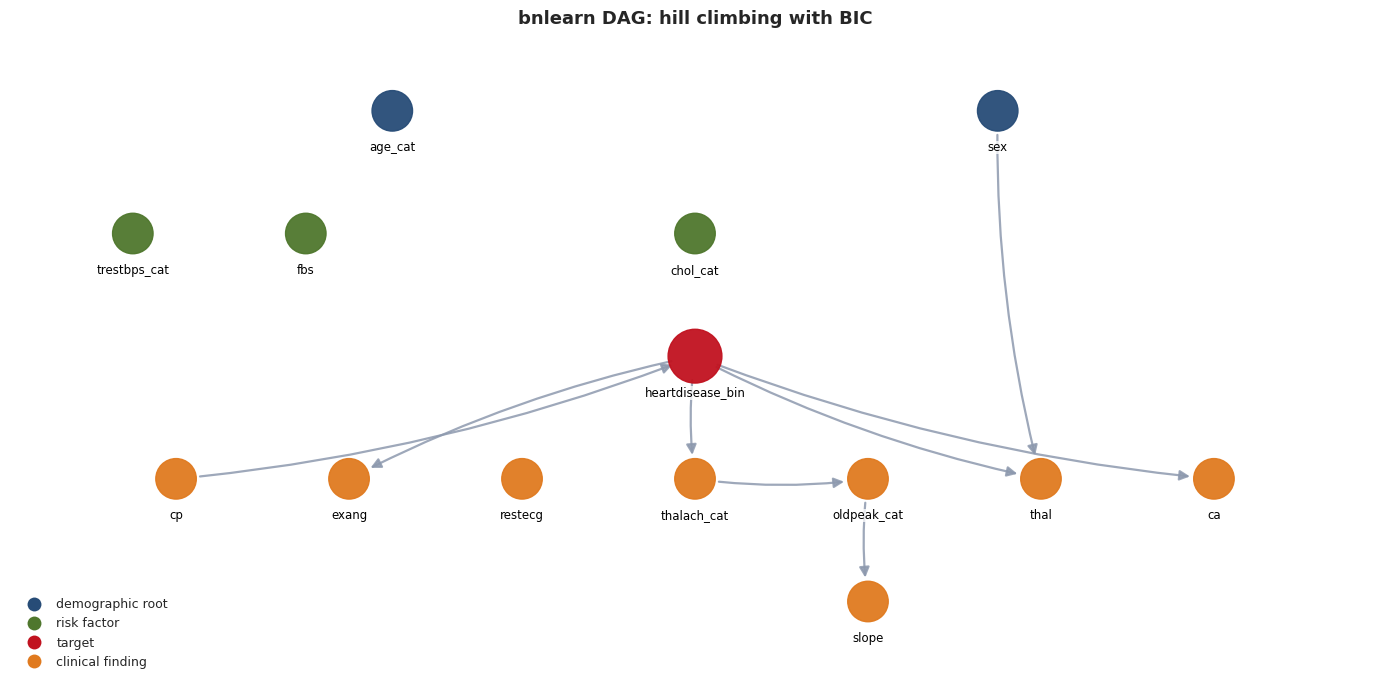

[bnlearn] >Set node properties.
[bnlearn] >Set edge properties.


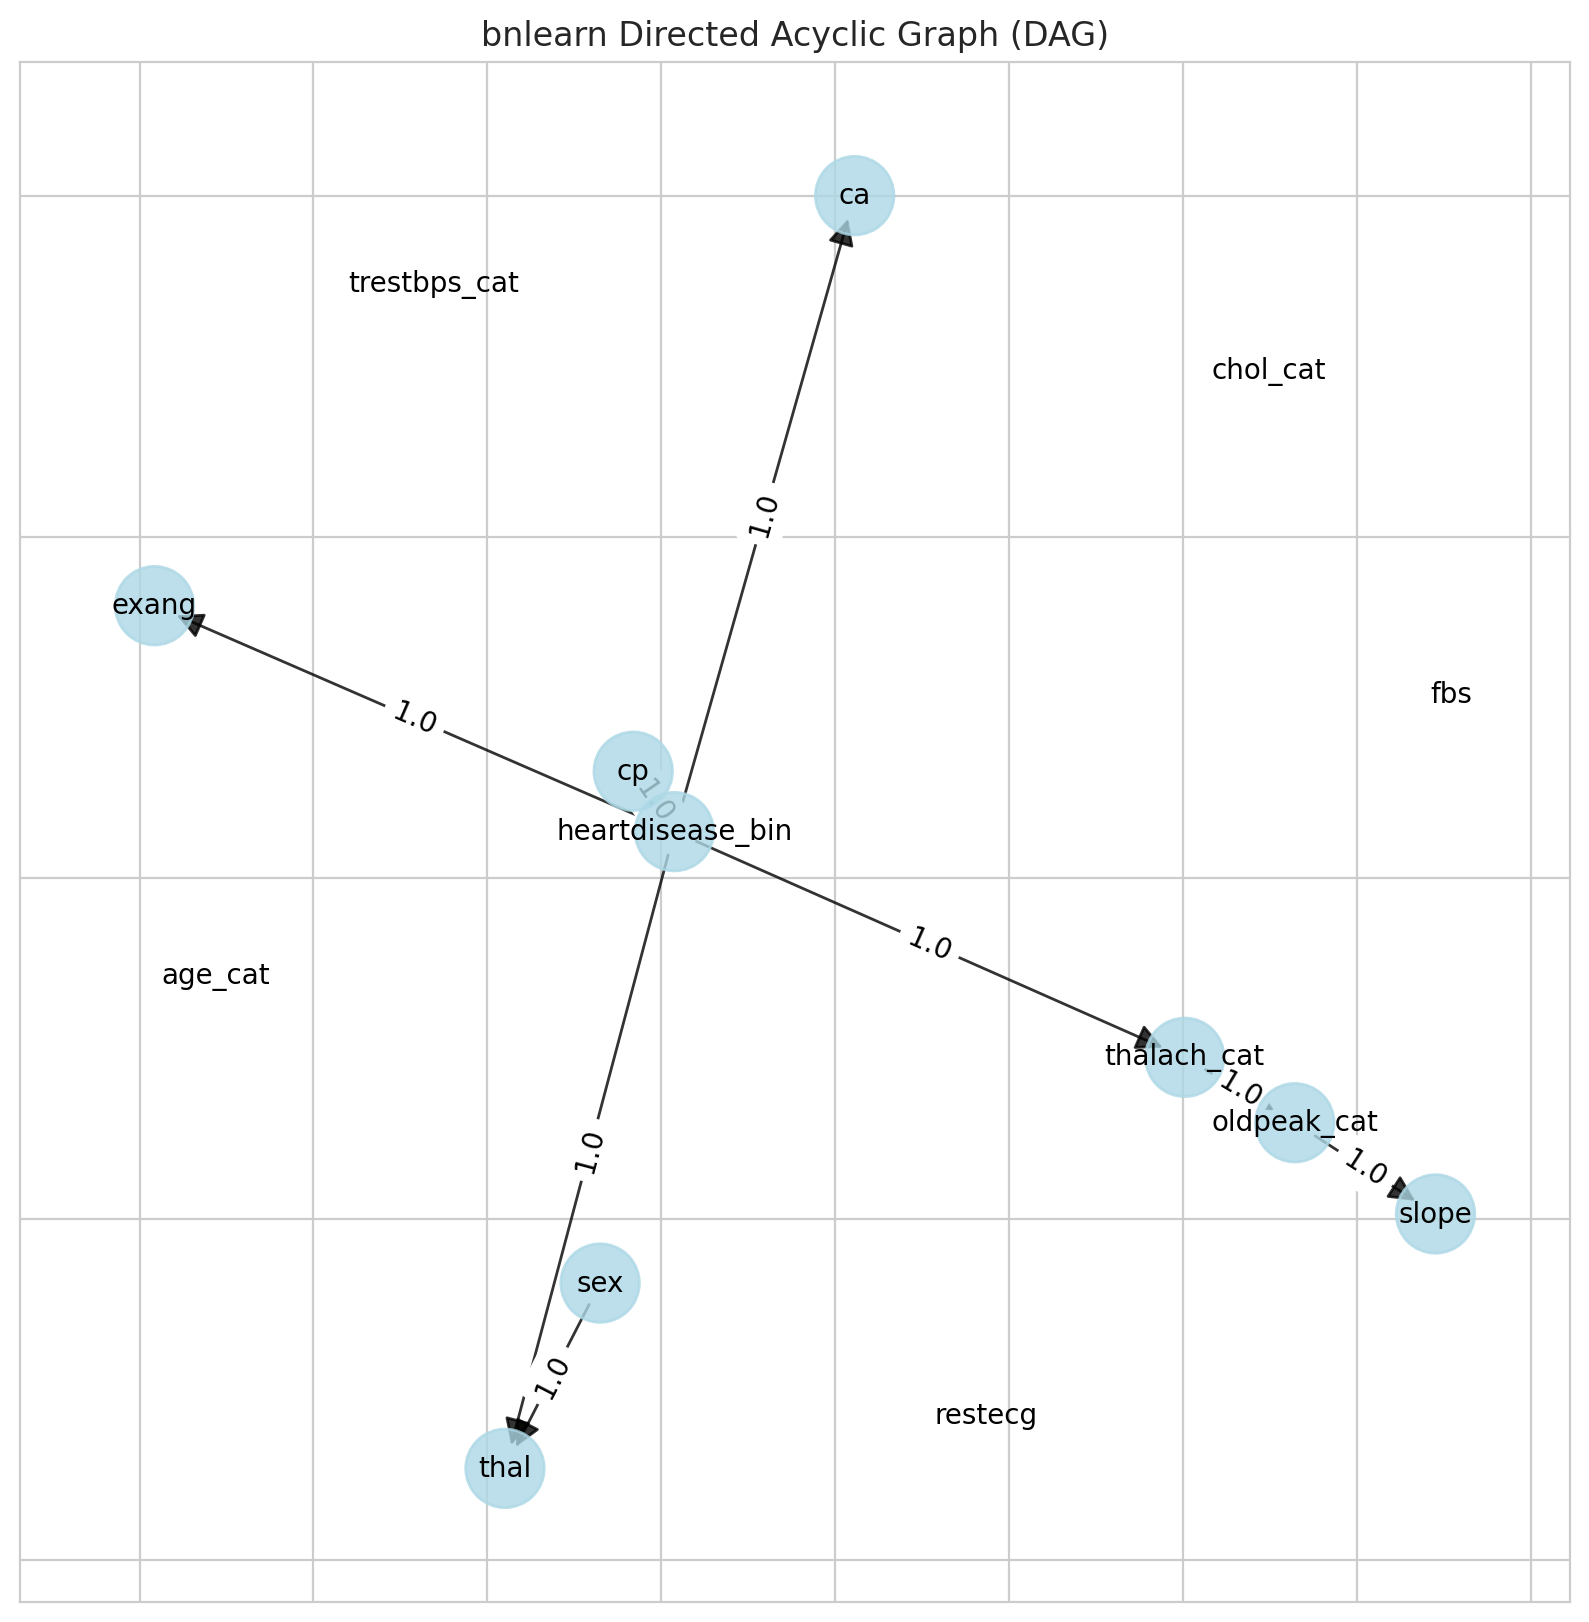

[05-09-2026 11:03:34] [setgraphviz.setgraphviz] [INFO] The OS is not supported to automatically set Graphviz in the system env.
[05-09-2026 11:03:34] [setgraphviz.setgraphviz] [INFO] The OS is not supported to automatically set Graphviz in the system env.
[05-09-2026 11:03:34] [setgraphviz.setgraphviz] [INFO] Graphviz path found in environment.
[05-09-2026 11:03:34] [setgraphviz.setgraphviz] [INFO] Graphviz path found in environment.


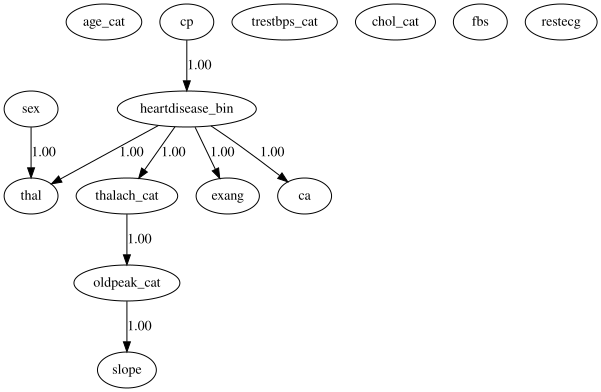

In [ ]:
learned_edges = edges_black
sl_learned = sl_black

learned_dag = BayesianNetwork(learned_edges)
learned_dag.add_nodes_from(MODEL_COLS)

connected = set()
for u, v in learned_edges:
    connected.add(u)
    connected.add(v)
isolated = [n for n in MODEL_COLS if n not in connected]

print("Learned DAG:", len(learned_edges), "edges")
print("Isolated nodes:", isolated)
print("Parents of target :", sorted(learned_dag.get_parents(TARGET)))
print("Children of target:", sorted(learned_dag.successors(TARGET)))
print("Markov blanket    :", sorted(learned_dag.get_markov_blanket(TARGET)))

fig, ax = plt.subplots(figsize=(14, 7))
plot_dag(learned_edges, "bnlearn DAG: hill climbing with BIC", ax=ax, legend=True)
plt.tight_layout(); plt.show()

bn.plot(sl_learned, verbose=0)
bn.plot_graphviz(sl_learned)

### 2.9 Comparing the two structures

In [ ]:
# Sort every edge into one of four buckets.
A = set(EXPERT_EDGES)
B = set(learned_edges)

# an edge counts as reversed if the same pair appears in both graphs, opposite directions
reversed_edges = set()
for u, v in A:
    if (v, u) in B:
        reversed_edges.add((u, v))

# the same reversed pairs written the way the learned graph has them,
# so they are not double counted as bnlearn-only below
reversed_in_b = set()
for u, v in reversed_edges:
    reversed_in_b.add((v, u))

rows = []
for u, v in sorted(A & B):
    rows.append({"edge": u + " -> " + v, "status": "in both"})
for u, v in sorted(reversed_edges):
    rows.append({"edge": u + " -> " + v, "status": "reversed in bnlearn"})
for u, v in sorted(A - B - reversed_edges):
    rows.append({"edge": u + " -> " + v, "status": "expert only"})
for u, v in sorted(B - A - reversed_in_b):
    rows.append({"edge": u + " -> " + v, "status": "bnlearn only"})

comparison = pd.DataFrame(rows)
display(comparison)
display(comparison["status"].value_counts().rename("edges").to_frame())

,edge,status
0,heartdisease_bin -> ca,in both
1,heartdisease_bin -> exang,in both
2,heartdisease_bin -> thal,in both
3,heartdisease_bin -> thalach_cat,in both
4,oldpeak_cat -> slope,in both
5,heartdisease_bin -> cp,reversed in bnlearn
6,age_cat -> chol_cat,expert only
7,age_cat -> fbs,expert only
8,age_cat -> heartdisease_bin,expert only
9,age_cat -> thalach_cat,expert only


,edges
status,
expert only,12
in both,5
bnlearn only,2
reversed in bnlearn,1


In [ ]:
# BIC on the same training data, and the size of each target's Markov blanket.
mb_e = set(expert_dag.get_markov_blanket(TARGET))
mb_l = set(learned_dag.get_markov_blanket(TARGET))

scores = pd.DataFrame([
    {"network": "expert", "edges": len(EXPERT_EDGES),
     "BIC_train": round(BIC_SCORE(train_bn).score(expert_dag), 1),
     "blanket_size": len(mb_e)},
    {"network": "bnlearn", "edges": len(learned_edges),
     "BIC_train": round(BIC_SCORE(train_bn).score(learned_dag), 1),
     "blanket_size": len(mb_l)},
])
display(scores)

print("In expert blanket only :", sorted(mb_e - mb_l))
print("In bnlearn blanket only:", sorted(mb_l - mb_e))

,network,edges,BIC_train,blanket_size
0,expert,18,-2869.2,10
1,bnlearn,8,-2769.9,6


In expert blanket only : ['age_cat', 'chol_cat', 'oldpeak_cat', 'restecg']
In bnlearn blanket only: []


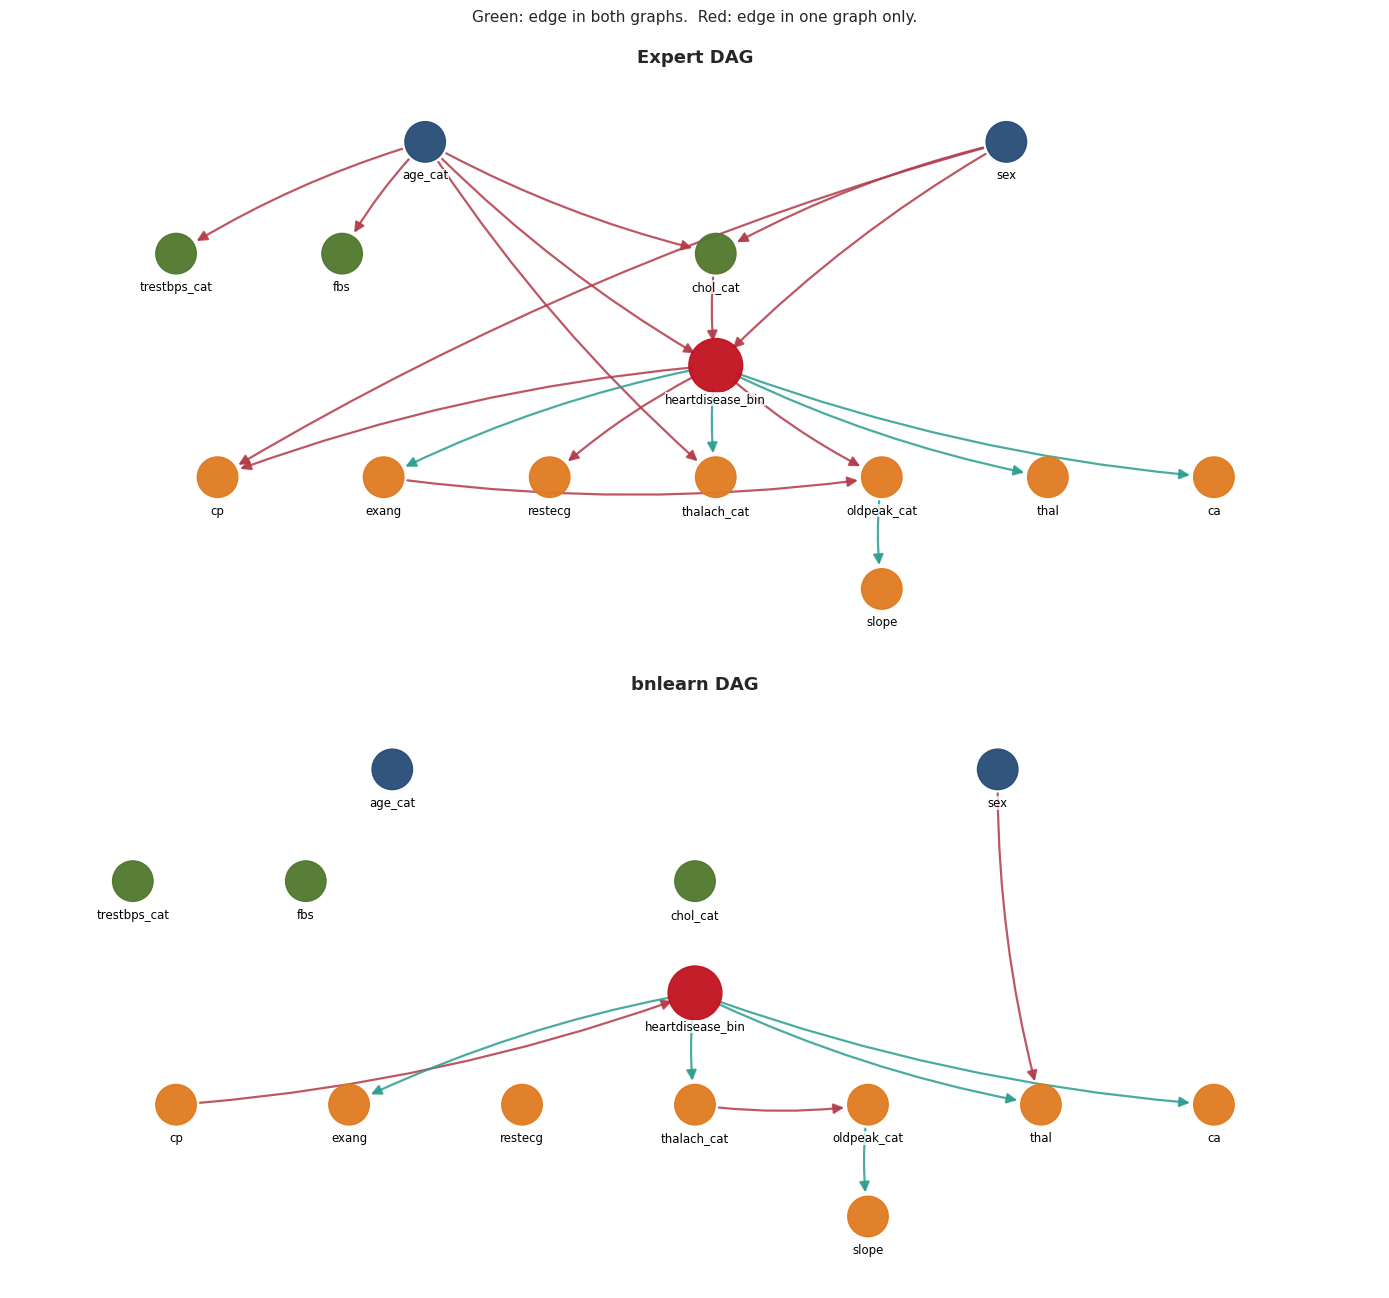

In [ ]:
# Both graphs on the same node positions.
shared = A & B

colors_e = {}
for e in EXPERT_EDGES:
    colors_e[e] = "#2a9d8f" if e in shared else "#b23a48"

colors_l = {}
for e in learned_edges:
    colors_l[e] = "#2a9d8f" if e in shared else "#b23a48"

fig, axes = plt.subplots(2, 1, figsize=(14, 13))
plot_dag(EXPERT_EDGES, "Expert DAG", ax=axes[0], edge_colors=colors_e)
plot_dag(learned_edges, "bnlearn DAG", ax=axes[1], edge_colors=colors_l)
fig.suptitle("Green: edge in both graphs.  Red: edge in one graph only.", fontsize=11, y=0.995)
plt.tight_layout(); plt.show()

The two graphs agree on five edges, all of them running from the target out to a clinical finding: ca, exang, thal and thalach, plus the link from ST depression to slope. These are the edges carrying the diagnostic signal, and it is worth noting that an algorithm working only from the data arrived at the same directions we did from clinical reasoning.

One edge is reversed. We drew heart disease causing chest pain type; the search drew chest pain type causing heart disease. Hill climbing scores a whole class of graphs that share the same statistical fit, and within that class the direction of some edges is simply not identifiable from observational data. The score cannot tell the two apart. Our direction is the defensible one, since a symptom does not cause the disease producing it, and this is a good illustration of why a learned DAG should not be read as a causal claim.

Twelve edges are ours alone. Most involve the variables BIC dropped altogether: age, blood pressure, cholesterol, fasting blood sugar and resting ECG are all left isolated in the learned graph. BIC charges around 2.7 per parameter at our sample size, so a weak association that costs several parameters gets rejected even when the underlying relationship is genuine. Age is the clearest case. It is the single strongest known risk factor for coronary artery disease, and the chi-square test on our own edge confirmed it at p below 0.001, yet the search still discarded it. That is a statement about statistical power on 222 rows, not about cardiology.

The two edges belonging only to the learned graph are sex to thal and maximum heart rate to ST depression. Neither is absurd. The second in particular is close to our own reasoning, since we linked exercise angina to ST depression on the grounds that both index the same ischaemic episode, and maximum heart rate belongs to that same exercise test.

On BIC the learned graph wins, minus 2769.9 against minus 2869.2. That was expected, because hill climbing optimises BIC directly on this training set, so the comparison is close to circular. The meaningful test is how each performs on the held-out data in Section 5.

The blanket comparison is the more interesting number. Ours contains 10 variables, theirs 6, and theirs is a strict subset of ours. There is nothing the algorithm treats as relevant that we do not. The four extra in ours are age, cholesterol, ST depression and resting ECG. So the disagreement is entirely about how much the sparser model is willing to pay for, not about which variables matter.

## 3. Parameter Learning

### 3.1 Choosing the prior

In [ ]:
# Fit CPTs on the training data only. Isolated nodes are kept so every variable gets a table.
def fit_params(edges, data, scoretype="k2"):
    connected = set()
    for u, v in edges:
        connected.add(u)
        connected.add(v)
    missing = [n for n in MODEL_COLS if n not in connected]

    dag = bn.make_DAG(list(edges), isolated_nodes=missing or None, verbose=0)
    out = bn.parameter_learning.fit(dag, data, methodtype="bayes",
                                    scoretype=scoretype, verbose=0)

    model = out["model"]
    for c in MODEL_COLS:
        if c in model.nodes():
            fitted = set(model.get_cpds(c).state_names[c])
            if fitted != set(STATE_NAMES[c]):
                print("  warning:", c, "fitted on", sorted(fitted))
    return out, model

# Compare the two priors on the target's CPT before choosing one.
prior_check = []
for st in ["bdeu", "k2"]:
    m = fit_params(EXPERT_EDGES, train_bn, scoretype=st)[1]
    v = m.get_cpds(TARGET).get_values()[1]
    prior_check.append({"prior": st,
                        "min P(disease)": round(v.min(), 3),
                        "max P(disease)": round(v.max(), 3),
                        "spread": round(v.max() - v.min(), 3)})
display(pd.DataFrame(prior_check))

,prior,min P(disease),max P(disease),spread
0,bdeu,0.428,0.663,0.234
1,k2,0.125,0.893,0.768


Fitting the same structure to the same training data under bnlearn's two Bayesian priors gives very different tables. Under bdeu the probability of disease varies only from 0.428 to 0.663 across all 24 parent configurations, a spread of 0.23. Under k2 it runs from 0.125 to 0.893, a spread of 0.77. The reason is that bnlearn passes an equivalent sample size of 1000 when bdeu is selected, so the prior carries the weight of 1000 imaginary uniform observations against our 222 real ones and pulls every cell toward 0.5. The k2 prior adds one pseudo-count per cell, roughly 48 across the table, enough to keep sparse cells from collapsing to zero without drowning the data. We fit both networks with k2.

### 3.2 Fitting both networks

In [ ]:
# Fit both networks with the k2 prior.
bn_expert,  expert_model  = fit_params(EXPERT_EDGES,  train_bn, scoretype="k2")
bn_learned, learned_model = fit_params(learned_edges, train_bn, scoretype="k2")

for name, m in [("expert", expert_model), ("bnlearn", learned_model)]:
    sums_ok = all(np.allclose(c.get_values().sum(axis=0), 1) for c in m.get_cpds())
    print(name, ":", len(m.get_cpds()), "CPTs, columns sum to 1:", sums_ok)

# Inventory of every CPT in both networks.
def cpt_inventory(model, label):
    rows = []
    for cpd in model.get_cpds():
        node = cpd.variables[0]
        parents = list(cpd.variables[1:])
        shape = " x ".join(str(len(cpd.state_names[v])) for v in cpd.variables)
        rows.append({"network": label,
                     "node": node,
                     "parents": ", ".join(sorted(parents)) if parents else "(root)",
                     "shape": shape,
                     "cells": int(np.prod(cpd.get_values().shape))})
    return pd.DataFrame(rows).sort_values("node").reset_index(drop=True)

inventory = pd.concat([cpt_inventory(expert_model, "expert"),
                       cpt_inventory(learned_model, "bnlearn")],
                      ignore_index=True)
display(inventory)
print(inventory.groupby("network")["cells"].sum().to_dict())

expert : 14 CPTs, columns sum to 1: True
bnlearn : 14 CPTs, columns sum to 1: True


,network,node,parents,shape,cells
0,expert,age_cat,(root),4,4
1,expert,ca,heartdisease_bin,4 x 2,8
2,expert,chol_cat,"age_cat, sex",3 x 4 x 2,24
3,expert,cp,"heartdisease_bin, sex",4 x 2 x 2,16
4,expert,exang,heartdisease_bin,2 x 2,4
5,expert,fbs,age_cat,2 x 4,8
6,expert,heartdisease_bin,"age_cat, chol_cat, sex",2 x 4 x 3 x 2,48
7,expert,oldpeak_cat,"exang, heartdisease_bin",3 x 2 x 2,12
8,expert,restecg,heartdisease_bin,3 x 2,6
9,expert,sex,(root),2,2


{'bnlearn': 77, 'expert': 183}


### 3.3 Conditional probability tables

In [ ]:
def cpd_to_df(cpd, decimals=3):
    node = cpd.variables[0]
    parents = list(cpd.variables[1:])
    states = cpd.state_names[node]
    idx = pd.Index(states, name=node)

    if not parents:
        vals = [cpd.get_value(**{node: s}) for s in states]
        return pd.DataFrame({"P": vals}, index=idx).round(decimals)

    combos = list(itertools.product(*[cpd.state_names[p] for p in parents]))
    data = []
    for s in states:
        row = []
        for c in combos:
            ev = dict(zip(parents, c))
            ev[node] = s
            row.append(cpd.get_value(**ev))
        data.append(row)

    cols = pd.MultiIndex.from_tuples(combos, names=parents)

### 3.4 The target's conditional probability table

In [ ]:
def target_risk_table(model, data, positive="1"):
    cpd = model.get_cpds(TARGET)
    parents = list(cpd.variables[1:])

    if not parents:
        return pd.DataFrame([{"P(disease)": round(cpd.get_value(**{TARGET: positive}), 3),
                              "n_train": len(data)}])

    rows = []
    for combo in itertools.product(*[cpd.state_names[p] for p in parents]):
        cfg = dict(zip(parents, combo))

        mask = np.ones(len(data), bool)
        for k, v in cfg.items():
            mask = mask & (data[k].values == v)

        ev = dict(cfg)
        ev[TARGET] = positive
        row = dict(cfg)
        row["P(disease)"] = round(cpd.get_value(**ev), 3)
        row["n_train"] = int(mask.sum())
        rows.append(row)

    out = pd.DataFrame(rows)
    return out.sort_values("P(disease)", ascending=False).reset_index(drop=True)


risk_expert = target_risk_table(expert_model, train_bn)
display(risk_expert)
print("Configurations with fewer than 5 training patients:",
      int((risk_expert["n_train"] < 5).sum()), "of", len(risk_expert))

risk_learned = target_risk_table(learned_model, train_bn)
display(risk_learned)

,age_cat,chol_cat,sex,P(disease),n_train
0,55-64,high,1,0.893,26
1,65+,desirable,1,0.750,2
2,65+,high,1,0.667,7
3,<45,desirable,1,0.600,8
4,55-64,borderline,1,0.565,21
5,45-54,high,1,0.552,27
6,55-64,high,0,0.520,23
7,55-64,borderline,0,0.500,4
8,65+,borderline,1,0.500,4
9,55-64,desirable,1,0.500,10


Configurations with fewer than 5 training patients: 9 of 24


,cp,P(disease),n_train
0,4,0.718,108
1,1,0.389,16
2,3,0.200,63
3,2,0.189,35


In our network the probability of disease is conditioned on age, cholesterol and sex, giving 24 combinations. The highest risk profile is men aged 55 to 64 with high cholesterol at 0.893, backed by 26 training patients. The lowest is men under 45 with borderline cholesterol at 0.125 on 6 patients. So patient background alone moves the diagnosis across most of the probability range before any test result is considered.

Nine of the 24 combinations rest on fewer than five patients, and those figures are closer to the prior than to anything the data established. Men aged 65 and over with desirable cholesterol appear at 0.750, but only 2 patients sit behind that number. We report the table in full and treat any row under about ten patients as indicative only.

Cholesterol does not order sensibly within the table. Men under 45 with desirable cholesterol reach 0.600, higher than several older groups with worse cholesterol. This is the same weakness the independence test picked up, now visible in the fitted probabilities, and it reflects that everyone in this sample had already been referred for angiography.

The learned network conditions the target on chest pain type alone, which gives four rows, all well supported. Asymptomatic patients sit at 0.718 on 108 cases, falling to 0.189 for atypical angina on 35. It is a cleaner table and better estimated than ours, but it says nothing about age or sex and treats a reported symptom as the cause of the disease rather than its consequence.

### 3.5 How much each finding moves the diagnosis

In [ ]:
def child_contrast(model, neg="0", pos="1"):
    rows = []
    for child in model.successors(TARGET):
        cpd = model.get_cpds(child)
        parents = list(cpd.variables[1:])
        others = [p for p in parents if p != TARGET]

        if others:
            combos = list(itertools.product(*[cpd.state_names[p] for p in others]))
        else:
            combos = [()]

        for combo in combos:
            oc = dict(zip(others, combo))
            held = ", ".join(k + "=" + v for k, v in oc.items()) if oc else "-"

            for state in cpd.state_names[child]:
                ev0 = dict(oc); ev0[child] = state; ev0[TARGET] = neg
                ev1 = dict(oc); ev1[child] = state; ev1[TARGET] = pos
                p0 = cpd.get_value(**ev0)
                p1 = cpd.get_value(**ev1)

                rows.append({"finding": child,
                             "state": state,
                             "held_fixed": held,
                             "P(state | no disease)": round(p0, 3),
                             "P(state | disease)": round(p1, 3),
                             "difference": round(p1 - p0, 3),
                             "likelihood_ratio": round(p1 / max(p0, 1e-9), 2)})

    out = pd.DataFrame(rows)
    return out.sort_values("difference", key=np.abs, ascending=False).reset_index(drop=True)


contrast = child_contrast(expert_model)
display(contrast.head(12))

,finding,state,held_fixed,P(state | no disease),P(state | disease),difference,likelihood_ratio
0,thal,3,-,0.756,0.267,-0.489,0.35
1,cp,4,sex=0,0.255,0.739,0.485,2.90
2,cp,4,sex=1,0.247,0.724,0.478,2.94
3,thal,7,-,0.187,0.648,0.461,3.46
4,ca,0,-,0.758,0.330,-0.428,0.44
5,cp,3,sex=0,0.473,0.087,-0.386,0.18
6,thalach_cat,high,age_cat=<45,0.692,0.308,-0.385,0.44
7,oldpeak_cat,marked,exang=1,0.318,0.684,0.366,2.15
8,exang,1,-,0.164,0.529,0.365,3.23
9,exang,0,-,0.836,0.471,-0.365,0.56


Reading the fitted CPTs of the target's children gives the evidential strength of every clinical finding. The table reports the probability of each finding under both disease states, their difference, and the ratio between them, which is the factor by which observing that finding multiplies the odds of disease.

A normal thallium scan is the single most informative result. It appears in 75.6% of patients without disease but only 26.7% of those with it, so seeing it cuts the odds of disease to roughly a third. The reverse holds for a reversible defect, which appears in 64.8% of diseased patients against 18.7% of healthy ones, a factor of 3.5 in favour of disease.

Asymptomatic chest pain is almost as strong, and notably the effect is the same in both sexes, 0.739 against 0.255 in women and 0.724 against 0.247 in men. This is worth stating because it is evidence against the edge we drew from sex into chest pain type. The CPT shows sex makes almost no difference here, which is consistent with that edge failing the independence test at p = 0.070.

Clear coronary arteries on fluoroscopy work like the normal thallium scan, present in 75.8% of healthy patients against 33% of diseased ones. Exercise angina runs the other way, 52.9% against 16.4%, a factor of 3.2.

The most interesting row is maximum heart rate, because the effect depends on age. In patients under 45 a low maximum heart rate is five times more likely under disease than without it. In the 45 to 54 group the factor falls to 3.5. This is the explaining away we predicted from the structure: a low maximum heart rate in a young patient demands an explanation, while in an older patient age already supplies one. A network without the age edge would treat both readings as equally alarming.

### 3.6 Testing the Markov blanket

In [ ]:
def query(model_dict, variables, evidence=None):
    return bn.inference.fit(model_dict, variables=variables,
                            evidence=evidence or {}, verbose=0).df

blanket = sorted(expert_model.get_markov_blanket(TARGET))
outside = sorted(set(MODEL_COLS) - set(blanket) - {TARGET})

patient = train_bn.iloc[0]
ev = {v: patient[v] for v in blanket}

base = float(query(bn_expert, [TARGET]).set_index(TARGET).loc["1", "p"])
p_blanket = float(query(bn_expert, [TARGET], ev).set_index(TARGET).loc["1", "p"])

print("Unconditional P(disease):", round(base, 4))
print("With the whole blanket observed:", round(p_blanket, 4))
print("\nAdding one variable from outside the blanket:")

for v in outside:
    results = []
    for st in STATE_NAMES[v]:
        ev2 = dict(ev)
        ev2[v] = st
        p = float(query(bn_expert, [TARGET], ev2).set_index(TARGET).loc["1", "p"])
        results.append(round(p, 4))
    print(" ", v, results)

Unconditional P(disease): 0.4804
With the whole blanket observed: 0.0051

Adding one variable from outside the blanket:
  fbs [0.0051, 0.0051]
  slope [0.0051, 0.0051, 0.0051]
  trestbps_cat [0.0051, 0.0051, 0.0051]


In Section 2 we identified fasting blood sugar, slope and resting blood pressure as the three variables lying outside the target's Markov blanket, and argued they should therefore contribute nothing to a diagnosis once the blanket is known. That is a claim about the structure, so the fitted parameters can settle it.

We take the first patient in the training set and condition on all ten blanket variables. The probability of disease comes to 0.0051, against an unconditional rate of 0.4804. We then add each outside variable to that evidence in turn, in every one of its states. The answer stays at 0.0051 in all eight cases, identical to four decimal places. The network is not merely downweighting these variables, it is ignoring them exactly, which is precisely the conditional independence the graph encodes.

Clinically this says that once a patient's age, sex, cholesterol and six main test results are on the table, a blood pressure reading and the slope of the ST segment add nothing further. The qualification matters: this holds only under full blanket evidence. Where the blanket is incomplete these variables do move the posterior, since slope still reaches the target through ST depression, and blood pressure and fasting blood sugar through age.

The size of the shift is worth noting in its own right. Background characteristics alone leave this patient near a coin flip at 0.48. The eight clinical findings take that to near certainty. Whatever the risk factors contribute, the diagnostic weight in this network sits overwhelmingly in the test results.

### 3.7 Ranking single pieces of evidence

In [ ]:
def posterior_lift(model_dict, data, positive="1", min_n=5):
    base = float(query(model_dict, [TARGET]).set_index(TARGET).loc[positive, "p"])

    rows = []
    for var in MODEL_COLS:
        if var == TARGET:
            continue
        for state in STATE_NAMES[var]:
            n = int((data[var].values == state).sum())
            if n < min_n:
                continue
            p = float(query(model_dict, [TARGET], {var: state}).set_index(TARGET).loc[positive, "p"])
            rows.append({"variable": var,
                         "state": state,
                         "n_train": n,
                         "P(disease | evidence)": round(p, 3),
                         "lift_vs_base": round(p / base, 2)})

    out = pd.DataFrame(rows)
    out = out.sort_values("P(disease | evidence)", ascending=False).reset_index(drop=True)
    return out, base


lift_expert, base_expert = posterior_lift(bn_expert, train_bn)
lift_learned, base_learned = posterior_lift(bn_learned, train_bn)

print("Base rate, expert:", round(base_expert, 3), " bnlearn:", round(base_learned, 3))

merged = lift_expert.merge(lift_learned, on=["variable", "state", "n_train"],
                           suffixes=(" [expert]", " [bnlearn]"))
display(merged.head(12))
display(merged.tail(8))

Base rate, expert: 0.48  bnlearn: 0.462


,variable,state,n_train,P(disease | evidence) [expert],lift_vs_base [expert],P(disease | evidence) [bnlearn],lift_vs_base [bnlearn]
0,ca,2,31,0.772,1.61,0.759,1.64
1,ca,3,14,0.764,1.59,0.751,1.62
2,thal,7,89,0.762,1.59,0.711,1.54
3,exang,1,73,0.749,1.56,0.735,1.59
4,cp,4,108,0.729,1.52,0.718,1.55
5,thalach_cat,low,71,0.703,1.46,0.700,1.51
6,ca,1,50,0.671,1.40,0.655,1.42
7,oldpeak_cat,marked,91,0.660,1.37,0.530,1.15
8,age_cat,55-64,89,0.638,1.33,0.462,1.00
9,thal,6,14,0.582,1.21,0.505,1.09


,variable,state,n_train,P(disease | evidence) [expert],lift_vs_base [expert],P(disease | evidence) [bnlearn],lift_vs_base [bnlearn]
30,sex,0,70,0.327,0.68,0.462,1.00
31,oldpeak_cat,none,70,0.313,0.65,0.369,0.80
32,ca,0,127,0.287,0.60,0.273,0.59
33,age_cat,<45,46,0.276,0.57,0.462,1.00
34,thalach_cat,high,69,0.272,0.57,0.241,0.52
35,thal,3,119,0.246,0.51,0.263,0.57
36,cp,3,63,0.222,0.46,0.200,0.43
37,cp,2,35,0.218,0.45,0.189,0.41


Conditioning on one variable at a time and reading the posterior gives a ranking of which observations matter most. Both networks start from a similar base rate, 0.480 in ours and 0.462 in the learned one.

The top of the ranking is the same in both. Two or three vessels visible on fluoroscopy raises the probability of disease to around 0.76, a reversible defect on the thallium scan to 0.762, exercise angina to 0.749, asymptomatic chest pain to 0.729. At the bottom, atypical or non-anginal chest pain, a normal thallium scan and clear arteries all pull the probability down to between 0.22 and 0.29. That both networks agree on the strongest and weakest evidence is reassuring, since they were built by completely different means.

Where they part company is on the variables the learned network dropped. Age between 55 and 64 lifts the probability to 0.638 in our network but leaves it at 0.462 in the learned one, exactly the base rate, because age is isolated there and carries no information at all. The same applies to resting ECG, and being female drops the probability to 0.327 in ours against no movement whatsoever in the learned network. The learned model is therefore blind to the two demographic variables that clinical practice treats as the starting point for cardiovascular risk assessment.

Marked ST depression shows a subtler version of the same effect: 0.660 in our network against 0.530 in the learned one. Both include it, but ours routes it directly from the target while the learned graph reaches it only through maximum heart rate, weakening the signal.

### 3.8 Saving the fitted networks

In [ ]:
with open("expert_dag_model.pkl", "wb") as f:
    pickle.dump(bn_expert, f)
print("saved expert_dag_model.pkl")

with open("bnlearn_dag_model.pkl", "wb") as f:
    pickle.dump(bn_learned, f)
print("saved bnlearn_dag_model.pkl")

context = {"target": TARGET,
           "model_cols": MODEL_COLS,
           "state_names": STATE_NAMES,
           "expert_edges": EXPERT_EDGES,
           "learned_edges": learned_edges,
           "train": train_bn,
           "test": test_bn,
           "random_state": RANDOM_STATE}

with open("bn_context.pkl", "wb") as f:
    pickle.dump(context, f)
print("saved bn_context.pkl")

with open("expert_dag_model.pkl", "rb") as f:
    reloaded = pickle.load(f)
print(query(reloaded, [TARGET]))

saved expert_dag_model.pkl
saved bnlearn_dag_model.pkl
saved bn_context.pkl
  heartdisease_bin        p
0                0  0.51959
1                1  0.48041


## 4. Inference

### 4.1 Posterior across combinations of clinical variables

In [ ]:
def posterior(model_dict, evidence):
    df = query(model_dict, [TARGET], evidence)
    return float(df.set_index(TARGET).loc["1", "p"])

GRID_VARS = ["sex", "cp", "exang", "thal", "ca"]
combos = list(itertools.product(*[STATE_NAMES[v] for v in GRID_VARS]))

rows = []
for combo in combos:
    ev = dict(zip(GRID_VARS, combo))

    mask = np.ones(len(train_bn), bool)
    for k, v in ev.items():
        mask = mask & (train_bn[k].values == v)

    r = dict(ev)
    r["P_expert"] = round(posterior(bn_expert, ev), 3)
    r["P_bnlearn"] = round(posterior(bn_learned, ev), 3)
    r["n_train"] = int(mask.sum())
    rows.append(r)

grid = pd.DataFrame(rows)
print(len(grid), "combinations evaluated in both networks")

ranked = grid.sort_values("P_expert", ascending=False).reset_index(drop=True)
print("\nTop 10 by expert network:")
display(ranked.head(10))
print("Bottom 10:")
display(ranked.tail(10))

supported = grid[grid["n_train"] >= 3].sort_values("P_expert", ascending=False)
print("\nHighest and lowest with at least 3 training patients behind them:")
display(pd.concat([supported.head(5), supported.tail(5)]))

192 combinations evaluated in both networks

Top 10 by expert network:


,sex,cp,exang,thal,ca,P_expert,P_bnlearn,n_train
0,1,4,1,7,3,0.993,0.985,3
1,1,4,1,7,2,0.993,0.986,8
2,1,4,1,7,1,0.989,0.977,9
3,1,4,1,6,2,0.985,0.970,0
4,1,4,1,6,3,0.984,0.969,0
5,0,4,1,7,2,0.983,0.996,3
6,0,4,1,7,3,0.982,0.996,0
7,1,4,1,6,1,0.975,0.951,2
8,0,4,1,7,1,0.972,0.994,0
9,1,1,1,7,2,0.970,0.946,0


Bottom 10:


,sex,cp,exang,thal,ca,P_expert,P_bnlearn,n_train
182,0,3,0,3,2,0.061,0.202,0
183,0,3,0,3,3,0.059,0.195,0
184,0,3,1,3,0,0.042,0.147,2
185,0,3,0,3,1,0.038,0.133,7
186,1,3,0,3,0,0.038,0.022,15
187,0,3,0,6,0,0.032,0.131,0
188,0,1,0,3,0,0.032,0.071,1
189,0,2,0,3,0,0.024,0.027,6
190,1,2,0,3,0,0.023,0.020,13
191,0,3,0,3,0,0.008,0.029,14



Highest and lowest with at least 3 training patients behind them:


,sex,cp,exang,thal,ca,P_expert,P_bnlearn,n_train
190,1,4,1,7,2,0.993,0.986,8
191,1,4,1,7,3,0.993,0.985,3
189,1,4,1,7,1,0.989,0.977,9
94,0,4,1,7,2,0.983,0.996,3
178,1,4,0,7,2,0.963,0.924,4
49,0,3,0,3,1,0.038,0.133,7
144,1,3,0,3,0,0.038,0.022,15
24,0,2,0,3,0,0.024,0.027,6
120,1,2,0,3,0,0.023,0.020,13
48,0,3,0,3,0,0.008,0.029,14


Running inference across all 192 combinations of sex, chest pain type, exercise angina, thallium result and vessels coloured gives a posterior that spans nearly the full probability range, from 0.008 to 0.993 in our network.

The highest is a male patient with asymptomatic chest pain, exercise angina and a reversible thallium defect. With two or three vessels coloured the posterior reaches 0.993, and with one vessel 0.989. These are not artefacts of thin data: 8, 3 and 9 training patients respectively sit behind those three rows. Every element of that profile is a strong individual indicator, and together they compound.

The lowest is a female patient with non-anginal pain, no exercise angina, a normal thallium scan and no vessels coloured, at 0.008 on 14 patients. The male equivalent sits at 0.038 on 15, the difference being the sex effect our network carries and the learned one does not. Atypical angina in place of non-anginal pain gives 0.023 for men and 0.024 for women.

Restricting to combinations with at least three training patients changes very little, which is worth noting. The extreme profiles are also the common ones, so the ranking is not being driven by empty cells.

The two networks broadly agree at both ends, but the disagreements are informative. For a female patient with asymptomatic chest pain, angina and a reversible defect, the learned network gives 0.996 against our 0.983. Ours applies a downward adjustment for female sex, the learned network cannot, since sex only reaches the target there through the thallium scan. At the other end, for the lowest male profile the learned network gives 0.022 against our 0.038, so it is more confident in ruling out disease where we hold back slightly on account of age and sex.

### 4.2 Changing one variable at a time

Baseline profile: {'sex': '1', 'cp': '4', 'exang': '1', 'thal': '7', 'ca': '0', 'oldpeak_cat': 'marked', 'thalach_cat': 'low', 'slope': '2'}
P(disease) expert: 0.99  bnlearn: 0.957


,variable,state,is_baseline,P_expert,change_expert,P_bnlearn,change_bnlearn
0,cp,2,False,0.883,-0.107,0.673,-0.284
1,thal,3,False,0.911,-0.079,0.779,-0.179
2,cp,3,False,0.927,-0.063,0.688,-0.269
3,exang,0,False,0.931,-0.059,0.797,-0.160
4,thalach_cat,high,False,0.938,-0.052,0.753,-0.204
5,oldpeak_cat,none,False,0.941,-0.049,0.957,0.000
6,cp,1,False,0.957,-0.033,0.849,-0.109
7,oldpeak_cat,mild,False,0.968,-0.022,0.957,0.000
8,thalach_cat,medium,False,0.972,-0.018,0.884,-0.073
9,sex,0,False,0.973,-0.017,0.989,0.031


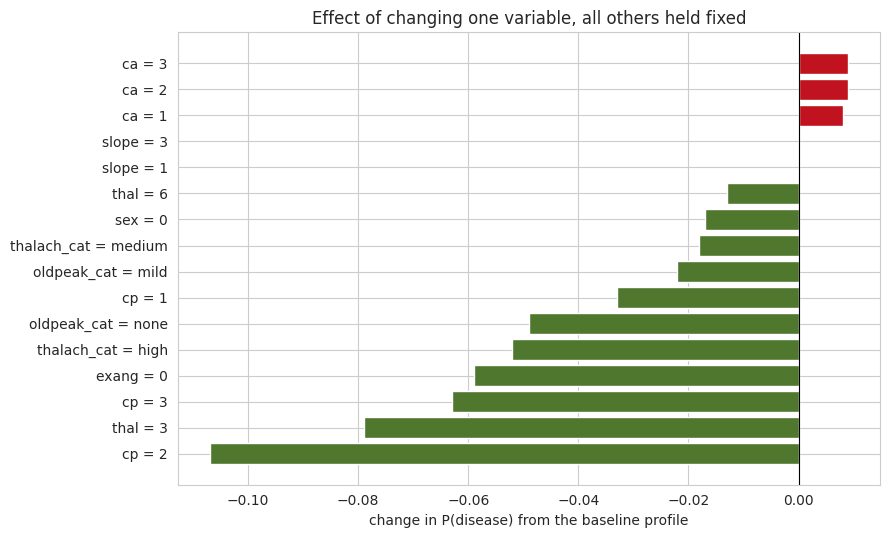

In [ ]:
BASELINE = {"sex": "1", "cp": "4", "exang": "1", "thal": "7", "ca": "0",
            "oldpeak_cat": "marked", "thalach_cat": "low", "slope": "2"}

base_e = posterior(bn_expert, BASELINE)
base_l = posterior(bn_learned, BASELINE)
print("Baseline profile:", BASELINE)
print("P(disease) expert:", round(base_e, 3), " bnlearn:", round(base_l, 3))

rows = []
for v in BASELINE:
    for st in STATE_NAMES[v]:
        ev = dict(BASELINE)
        ev[v] = st
        pe = posterior(bn_expert, ev)
        pl = posterior(bn_learned, ev)
        rows.append({"variable": v,
                     "state": st,
                     "is_baseline": st == BASELINE[v],
                     "P_expert": round(pe, 3),
                     "change_expert": round(pe - base_e, 3),
                     "P_bnlearn": round(pl, 3),
                     "change_bnlearn": round(pl - base_l, 3)})

sens = pd.DataFrame(rows)
display(sens.sort_values("change_expert").reset_index(drop=True))

tor = sens[~sens["is_baseline"]].copy()
tor["label"] = tor["variable"] + " = " + tor["state"]
tor = tor.sort_values("change_expert")

fig, ax = plt.subplots(figsize=(9, 0.28 * len(tor) + 1))
colors = np.where(tor["change_expert"] >= 0, "#c1121f", "#4f772d")
ax.barh(tor["label"], tor["change_expert"], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("change in P(disease) from the baseline profile")
ax.set_title("Effect of changing one variable, all others held fixed")
plt.tight_layout(); plt.show()

We fix a high-risk profile: a male patient with asymptomatic chest pain, exercise angina, a reversible thallium defect, no vessels coloured, marked ST depression, low maximum heart rate and a flat slope. Our network gives this patient a probability of 0.990, while the learned network gives 0.957. We then change one variable at a time and keep everything else the same.

The biggest change in our network comes from chest pain type. Changing asymptomatic chest pain to atypical angina lowers the probability by 0.107, while changing it to non-anginal pain lowers it by 0.063. Changing the thallium result from a reversible defect to a normal scan lowers the probability by 0.079. Removing exercise angina lowers it by 0.059.

The important point is that each change on its own has a fairly small effect. When several findings already point to high risk, changing only one of them does not change the overall result very much. Even the largest drop leaves the probability at 0.883. This shows how the different pieces of evidence work together in a Bayesian network. A strong risk profile can therefore remain high even when one result suggests lower risk. Several changes in the opposite direction would be needed to make a much bigger difference.

Vessels coloured increases the probability because the starting profile already has no vessels coloured. Changing from none to two vessels coloured increases the probability by only 0.009. This is also because the starting probability of 0.990 is already very high, so there is little room for it to increase.

Slope has no effect, with a change of 0.000 across all three states. This is linked to the Markov blanket result discussed in Section 3. Since marked ST depression is already known, changing the slope does not provide any extra information about the disease probability in our network.

The learned network reacts much more strongly to the same changes. Changing chest pain from asymptomatic to atypical angina lowers its probability by 0.284, compared with 0.107 in our network. Changing the thallium result to normal lowers its probability by 0.179, compared with 0.079 in our network. The learned network has only six variables directly linked to the target, so each variable has a larger effect on the final probability.

The learned network also gives a different result when sex is changed. Changing the patient from male to female increases the probability from 0.957 to 0.989. This is the opposite of what would normally be expected clinically. This happens because sex is only linked to the disease through the thallium result in the learned network, rather than being directly linked to the disease.

ST depression also has no effect in the learned network, but for a different reason. In this network, ST depression is not directly linked to the disease. Its only link to the disease is through maximum heart rate, which is already known. Therefore, changing ST depression does not change the final probability.

### 4.3 Reverse inference, given the patient has disease

In [ ]:
for var in ["cp", "thal", "exang", "ca"]:
    d1 = query(bn_expert, [var], {TARGET: "1"}).set_index(var)["p"]
    d0 = query(bn_expert, [var], {TARGET: "0"}).set_index(var)["p"]
    l1 = query(bn_learned, [var], {TARGET: "1"}).set_index(var)["p"]
    l0 = query(bn_learned, [var], {TARGET: "0"}).set_index(var)["p"]

    out = pd.DataFrame({"P(x | disease) expert": d1.round(3),
                        "P(x | no disease) expert": d0.round(3),
                        "P(x | disease) bnlearn": l1.round(3),
                        "P(x | no disease) bnlearn": l0.round(3)})
    print("\n" + var)
    display(out)


cp


,P(x | disease) expert,P(x | no disease) expert,P(x | disease) bnlearn,P(x | no disease) bnlearn
cp,,,,
1,0.072,0.095,0.063,0.086
2,0.073,0.243,0.065,0.240
3,0.127,0.412,0.122,0.421
4,0.727,0.250,0.749,0.253



thal


,P(x | disease) expert,P(x | no disease) expert,P(x | disease) bnlearn,P(x | no disease) bnlearn
thal,,,,
3,0.267,0.756,0.295,0.711
6,0.086,0.057,0.086,0.072
7,0.648,0.187,0.619,0.217



exang


,P(x | disease) expert,P(x | no disease) expert,P(x | disease) bnlearn,P(x | no disease) bnlearn
exang,,,,
0,0.471,0.836,0.471,0.836
1,0.529,0.164,0.529,0.164



ca


,P(x | disease) expert,P(x | no disease) expert,P(x | disease) bnlearn,P(x | no disease) bnlearn
ca,,,,
0,0.330,0.758,0.330,0.758
1,0.321,0.145,0.321,0.145
2,0.236,0.065,0.236,0.065
3,0.113,0.032,0.113,0.032


Running the query in the other direction asks what a patient with heart disease is likely to look like clinically, rather than what the findings say about the disease.

Chest pain type is the clearest. 72.7% of diseased patients present as asymptomatic, against 25.0% of those without disease. Typical angina appears in only 7.2% of diseased patients. The clinical reading is that classic chest pain is a poor screening symptom in this population, and its absence should not be reassuring.

The thallium scan gives a reversible defect in 64.8% of diseased patients against 18.7% of healthy ones, with a normal scan appearing in only 26.7% of the diseased group against 75.6% of the healthy.

Exercise angina is present in 52.9% of diseased patients and 16.4% of healthy ones. That is close to a coin flip within the diseased group, so its absence rules very little out even though its presence is informative.

Vessels coloured behaves as an ordered severity measure, which is a good sign the variable is doing what it should. Clear arteries appear in 75.8% of healthy patients but only 33.0% of diseased ones, and the proportion rises steadily with the count.

The two networks give nearly identical answers on exang and ca, since both link them directly to the target with the same parent set. They differ slightly on cp and thal, where the learned graph orients the edges differently, but the direction and magnitude of every effect survive.

### 4.4 Agreement between the two networks

Correlation between the two networks: 0.876
Mean absolute difference: 0.119
Largest difference: 0.459

Where they disagree most:


,sex,cp,exang,thal,ca,P_expert,P_bnlearn,n_train,abs_diff
57,0,3,0,7,1,0.278,0.737,1,0.459
68,0,3,1,7,0,0.303,0.760,0,0.457
59,0,3,0,7,3,0.379,0.817,0,0.438
58,0,3,0,7,2,0.389,0.823,0,0.434
54,0,3,0,6,2,0.217,0.558,0,0.341
55,0,3,0,6,3,0.210,0.548,0,0.338
8,0,1,0,7,0,0.247,0.584,0,0.337
65,0,3,1,6,1,0.489,0.814,0,0.325


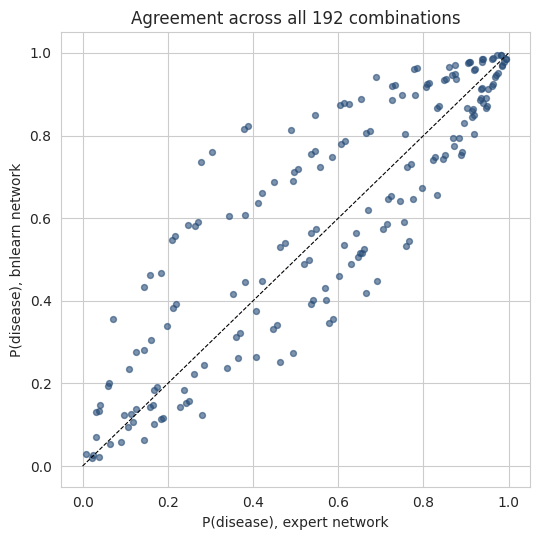

In [ ]:
grid["abs_diff"] = (grid["P_expert"] - grid["P_bnlearn"]).abs()

print("Correlation between the two networks:", round(grid["P_expert"].corr(grid["P_bnlearn"]), 3))
print("Mean absolute difference:", round(grid["abs_diff"].mean(), 3))
print("Largest difference:", round(grid["abs_diff"].max(), 3))

print("\nWhere they disagree most:")
display(grid.sort_values("abs_diff", ascending=False).head(8))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(grid["P_expert"], grid["P_bnlearn"], s=18, alpha=.6, color="#274c77")
ax.plot([0, 1], [0, 1], "k--", lw=.8)
ax.set_xlabel("P(disease), expert network")
ax.set_ylabel("P(disease), bnlearn network")
ax.set_title("Agreement across all " + str(len(grid)) + " combinations")
plt.tight_layout(); plt.show()

### 4.5 Decision table

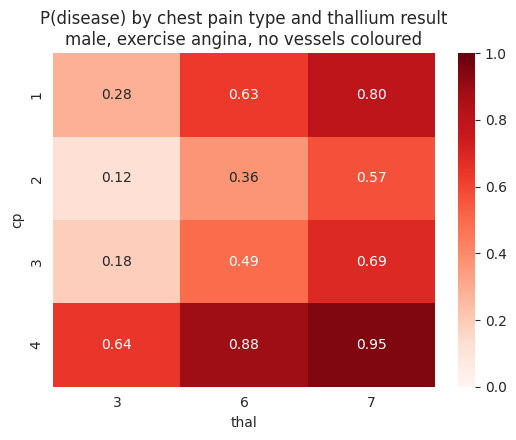

In [ ]:
sub = grid[(grid["sex"] == "1") & (grid["exang"] == "1") & (grid["ca"] == "0")]
hm = sub.pivot(index="cp", columns="thal", values="P_expert")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(hm, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, ax=ax)
ax.set_title("P(disease) by chest pain type and thallium result\nmale, exercise angina, no vessels coloured")
plt.tight_layout(); plt.show()

## 5. Model Evaluation

We now use both networks as classifiers on the 75 test patients held back in Section 1. For each patient we condition on all thirteen observed variables and read off the posterior probability of disease, which gives a score between 0 and 1 rather than a bare prediction. That lets us evaluate at any decision threshold and compute ROC and precision-recall curves, not just a single confusion matrix.

### 5.1 Posterior probabilities on the test set

In [ ]:
EV_COLS = [c for c in MODEL_COLS if c != TARGET]

def predict_proba(model_dict, data):
    out = []
    for _, row in data.iterrows():
        ev = {c: row[c] for c in EV_COLS}
        out.append(posterior(model_dict, ev))
    return np.array(out)

p_expert = predict_proba(bn_expert, test_bn)
p_bnlearn = predict_proba(bn_learned, test_bn)
y_true = test_bn[TARGET].astype(int).values

print("Test patients:", len(y_true), " actual disease rate:", round(y_true.mean(), 3))
display(pd.DataFrame({"actual": y_true[:10],
                      "P_expert": p_expert[:10].round(3),
                      "P_bnlearn": p_bnlearn[:10].round(3)}))

Test patients: 75  actual disease rate: 0.467


,actual,P_expert,P_bnlearn
0,1,0.977,0.989
1,1,0.960,0.967
2,1,0.943,0.952
3,0,0.052,0.172
4,1,0.140,0.380
5,0,0.000,0.011
6,0,0.003,0.011
7,1,0.987,0.966
8,0,0.012,0.008
9,1,0.981,0.817


### 5.2 Classification metrics

In [ ]:
def metrics_row(name, y, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    return {"model": name,
            "threshold": thr,
            "accuracy": round(accuracy_score(y, yhat), 3),
            "precision": round(precision_score(y, yhat, zero_division=0), 3),
            "recall": round(recall_score(y, yhat), 3),
            "f1": round(f1_score(y, yhat), 3),
            "roc_auc": round(roc_auc_score(y, p), 3),
            "pr_auc": round(average_precision_score(y, p), 3)}

results = pd.DataFrame([metrics_row("expert", y_true, p_expert),
                        metrics_row("bnlearn", y_true, p_bnlearn)])
display(results)

for name, p in [("expert", p_expert), ("bnlearn", p_bnlearn)]:
    print("\n" + name)
    print(classification_report(y_true, (p >= 0.5).astype(int),
                                target_names=["no disease", "disease"]))

,model,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
0,expert,0.5,0.813,0.839,0.743,0.788,0.920,0.902
1,bnlearn,0.5,0.853,0.900,0.771,0.831,0.922,0.903



expert
              precision    recall  f1-score   support

  no disease       0.80      0.88      0.83        40
     disease       0.84      0.74      0.79        35

    accuracy                           0.81        75
   macro avg       0.82      0.81      0.81        75
weighted avg       0.82      0.81      0.81        75


bnlearn
              precision    recall  f1-score   support

  no disease       0.82      0.93      0.87        40
     disease       0.90      0.77      0.83        35

    accuracy                           0.85        75
   macro avg       0.86      0.85      0.85        75
weighted avg       0.86      0.85      0.85        75



### 5.3 Confusion matrices

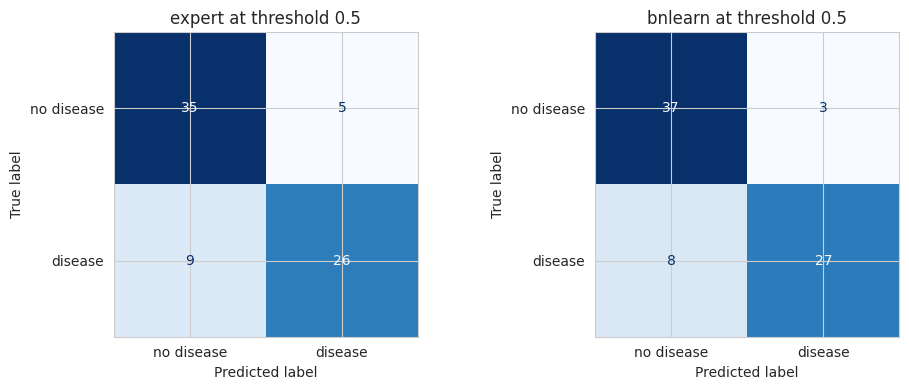

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, p) in zip(axes, [("expert", p_expert), ("bnlearn", p_bnlearn)]):
    cm = confusion_matrix(y_true, (p >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["no disease", "disease"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name + " at threshold 0.5")
plt.tight_layout(); plt.show()

### 5.4 ROC and precision-recall curves

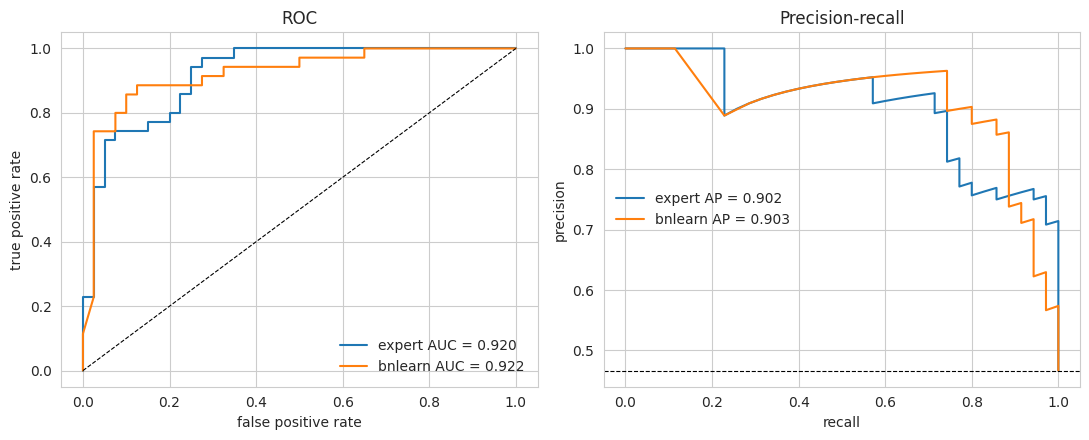

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, p in [("expert", p_expert), ("bnlearn", p_bnlearn)]:
    fpr, tpr, _ = roc_curve(y_true, p)
    axes[0].plot(fpr, tpr, label=name + " AUC = %.3f" % roc_auc_score(y_true, p))

    prec, rec, _ = precision_recall_curve(y_true, p)
    axes[1].plot(rec, prec, label=name + " AP = %.3f" % average_precision_score(y_true, p))

axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set_xlabel("false positive rate")
axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC")
axes[0].legend(frameon=False)

axes[1].axhline(y_true.mean(), ls="--", c="k", lw=0.8)
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall")
axes[1].legend(frameon=False)

plt.tight_layout(); plt.show()

### 5.5 Choosing a decision threshold

,threshold,accuracy,precision,recall,f1
0,0.20,0.827,0.762,0.914,0.831
1,0.25,0.800,0.750,0.857,0.800
2,0.30,0.787,0.757,0.800,0.778
3,0.35,0.800,0.794,0.771,0.783
4,0.40,0.813,0.818,0.771,0.794
5,0.45,0.813,0.818,0.771,0.794
6,0.50,0.813,0.839,0.743,0.788
7,0.55,0.813,0.839,0.743,0.788
8,0.60,0.840,0.897,0.743,0.812
9,0.65,0.827,0.893,0.714,0.794


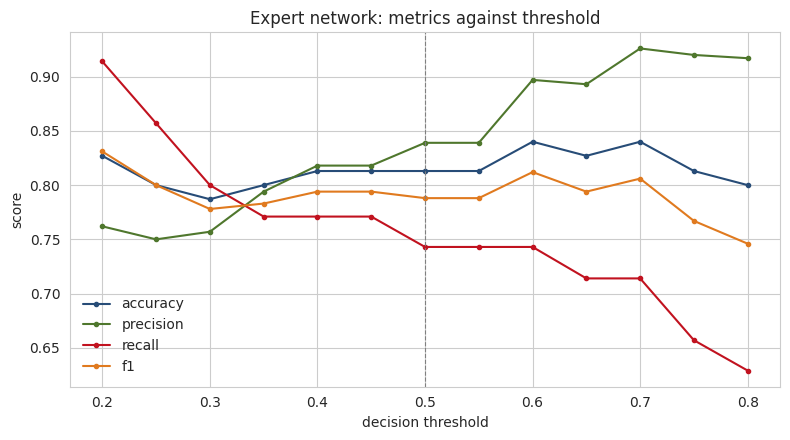

In [ ]:
rows = []
for thr in np.arange(0.20, 0.81, 0.05):
    rows.append(metrics_row("expert", y_true, p_expert, round(thr, 2)))
thr_table = pd.DataFrame(rows)
display(thr_table[["threshold", "accuracy", "precision", "recall", "f1"]])

fig, ax = plt.subplots(figsize=(8, 4.5))
for m, c in [("accuracy", "#274c77"), ("precision", "#4f772d"),
             ("recall", "#c1121f"), ("f1", "#e07a1f")]:
    ax.plot(thr_table["threshold"], thr_table[m], marker="o", ms=3, label=m, color=c)
ax.axvline(0.5, ls="--", c="grey", lw=0.8)
ax.set_xlabel("decision threshold")
ax.set_ylabel("score")
ax.set_title("Expert network: metrics against threshold")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### 5.6 Overall comparison

In [ ]:
cells_expert = int(inventory[inventory["network"] == "expert"]["cells"].sum())
cells_bnlearn = int(inventory[inventory["network"] == "bnlearn"]["cells"].sum())

summary = pd.DataFrame([
    {"criterion": "edges",
     "expert": len(EXPERT_EDGES), "bnlearn": len(learned_edges)},
    {"criterion": "variables in Markov blanket",
     "expert": len(expert_model.get_markov_blanket(TARGET)),
     "bnlearn": len(learned_model.get_markov_blanket(TARGET))},
    {"criterion": "CPT cells",
     "expert": cells_expert, "bnlearn": cells_bnlearn},
    {"criterion": "BIC on training data",
     "expert": round(BIC_SCORE(train_bn).score(expert_dag), 1),
     "bnlearn": round(BIC_SCORE(train_bn).score(learned_dag), 1)},
    {"criterion": "test accuracy",
     "expert": results.loc[0, "accuracy"], "bnlearn": results.loc[1, "accuracy"]},
    {"criterion": "test precision",
     "expert": results.loc[0, "precision"], "bnlearn": results.loc[1, "precision"]},
    {"criterion": "test recall",
     "expert": results.loc[0, "recall"], "bnlearn": results.loc[1, "recall"]},
    {"criterion": "test F1",
     "expert": results.loc[0, "f1"], "bnlearn": results.loc[1, "f1"]},
    {"criterion": "test ROC-AUC",
     "expert": results.loc[0, "roc_auc"], "bnlearn": results.loc[1, "roc_auc"]},
    {"criterion": "test PR-AUC",
     "expert": results.loc[0, "pr_auc"], "bnlearn": results.loc[1, "pr_auc"]},
])
display(summary)

,criterion,expert,bnlearn
0,edges,18.000,8.000
1,variables in Markov blanket,10.000,6.000
2,CPT cells,183.000,77.000
3,BIC on training data,-2869.200,-2769.900
4,test accuracy,0.813,0.853
5,test precision,0.839,0.900
6,test recall,0.743,0.771
7,test F1,0.788,0.831
8,test ROC-AUC,0.920,0.922
9,test PR-AUC,0.902,0.903
